**Week 1 – Data Exploration & Preparation**

In [3]:
#import required Libraries
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
import os

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

In [4]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:
from pathlib import Path
import os

PROJECT_DIR = Path(os.environ.get("RETAIL_PROJECT_DIR", Path.cwd())).resolve()
if not (PROJECT_DIR / "data").is_dir():
    PROJECT_DIR = next(
        (parent for parent in PROJECT_DIR.parents if (parent / "data").is_dir()),
        Path("/content/drive/MyDrive/Colab Notebooks/Retail Sales Prediction")
    )
DATA_DIR = PROJECT_DIR / "data"

file_path = str(DATA_DIR)

In [6]:
#Load the data

df = pd.read_csv(os.path.join(file_path, "online_retail.csv"))

In [7]:
df.head(5)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [8]:
df.shape

(525461, 8)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 525461 entries, 0 to 525460
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Invoice      525461 non-null  object 
 1   StockCode    525461 non-null  object 
 2   Description  522533 non-null  object 
 3   Quantity     525461 non-null  int64  
 4   InvoiceDate  525461 non-null  object 
 5   Price        525461 non-null  float64
 6   Customer ID  417534 non-null  float64
 7   Country      525461 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 32.1+ MB


In [10]:
df.describe()

,Quantity,Price,Customer ID
count,525461.000000,525461.000000,417534.000000
mean,10.337667,4.688834,15360.645478
std,107.424110,146.126914,1680.811316
min,-9600.000000,-53594.360000,12346.000000
25%,1.000000,1.250000,13983.000000
50%,3.000000,2.100000,15311.000000
75%,10.000000,4.210000,16799.000000
max,19152.000000,25111.090000,18287.000000


In [11]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Invoice,525461,28816,537434,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,525461,4632,85123A,3516,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,522533,4681,WHITE HANGING HEART T-LIGHT HOLDER,3549,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,525461.0,NaN,NaN,NaN,10.337667,107.42411,-9600.0,1.0,3.0,10.0,19152.0
InvoiceDate,525461,25296,12/6/2010 16:57,675,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Price,525461.0,NaN,NaN,NaN,4.688834,146.126914,-53594.36,1.25,2.1,4.21,25111.09
Customer ID,417534.0,NaN,NaN,NaN,15360.645478,1680.811316,12346.0,13983.0,15311.0,16799.0,18287.0
Country,525461,40,United Kingdom,485852,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [12]:
# Check datatypes
df.dtypes

,0
Invoice,object
StockCode,object
Description,object
Quantity,int64
InvoiceDate,object
Price,float64
Customer ID,float64
Country,object


In [13]:
# Check unique values
for col in df.columns:
    print(f"{col}: {df[col].nunique()} unique values")

Invoice: 28816 unique values
StockCode: 4632 unique values
Description: 4681 unique values
Quantity: 825 unique values
InvoiceDate: 25296 unique values
Price: 1606 unique values
Customer ID: 4383 unique values
Country: 40 unique values


In [14]:
# Find missing Values
df.isnull().sum()

,0
Invoice,0
StockCode,0
Description,2928
Quantity,0
InvoiceDate,0
Price,0
Customer ID,107927
Country,0


In [15]:
missing = df.isnull().sum()
missing_pct = (missing /len(df)*100).round(2)

missing_df = pd.DataFrame({
    "Missing Count": missing,
    "Missing %": missing_pct
}).sort_values("Missing %", ascending=False)

missing_df[missing_df["Missing Count"] > 0]


,Missing Count,Missing %
Customer ID,107927,20.54
Description,2928,0.56


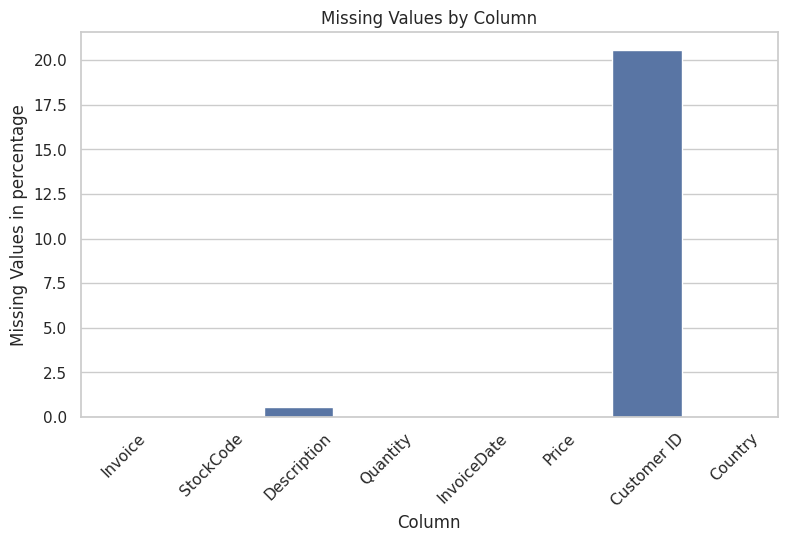

In [16]:
plt.figure(figsize=(9,5))

sns.barplot(
    x=missing_pct.index,
    y=missing_pct.values
)

plt.title("Missing Values by Column")
plt.xlabel("Column")
plt.ylabel("Missing Values in percentage")
plt.xticks(rotation=45)
plt.show()

# Distribution Analysis

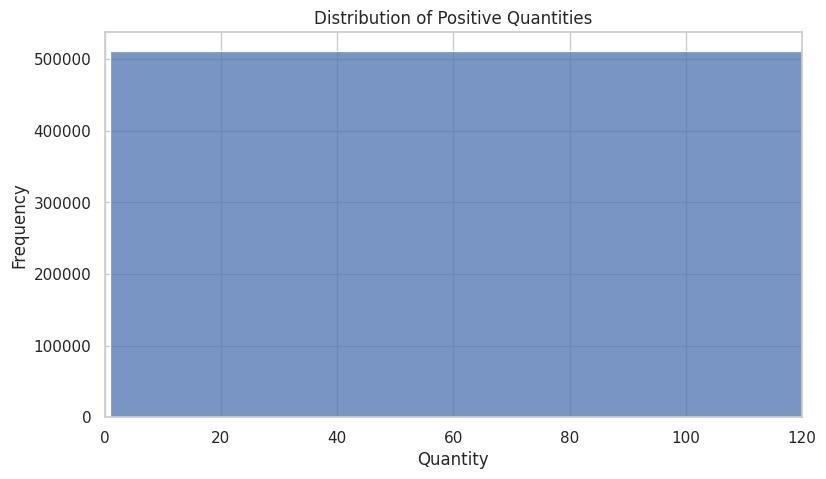

In [17]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df[df["Quantity"] > 0],
    x="Quantity",
    bins=50
)

plt.xlim(
    0,
    df.loc[df["Quantity"] > 0, "Quantity"].quantile(0.99)
)

plt.title("Distribution of Positive Quantities")
plt.xlabel("Quantity")
plt.ylabel("Frequency")
plt.show()

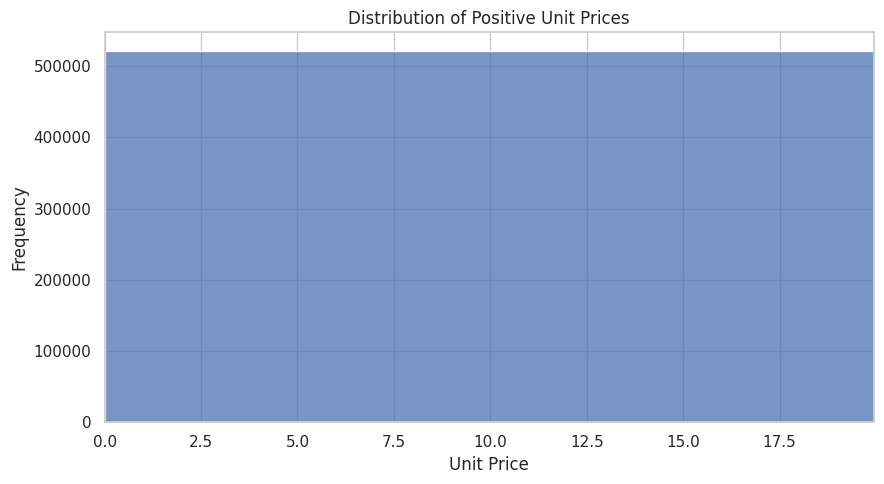

In [18]:
# Unit price distribution

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df[df["Price"] > 0],
    x="Price",
    bins=50
)

plt.xlim(
    0,
    df.loc[df["Price"] > 0, "Price"].quantile(0.99)
)

plt.title("Distribution of Positive Unit Prices")
plt.xlabel("Unit Price")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

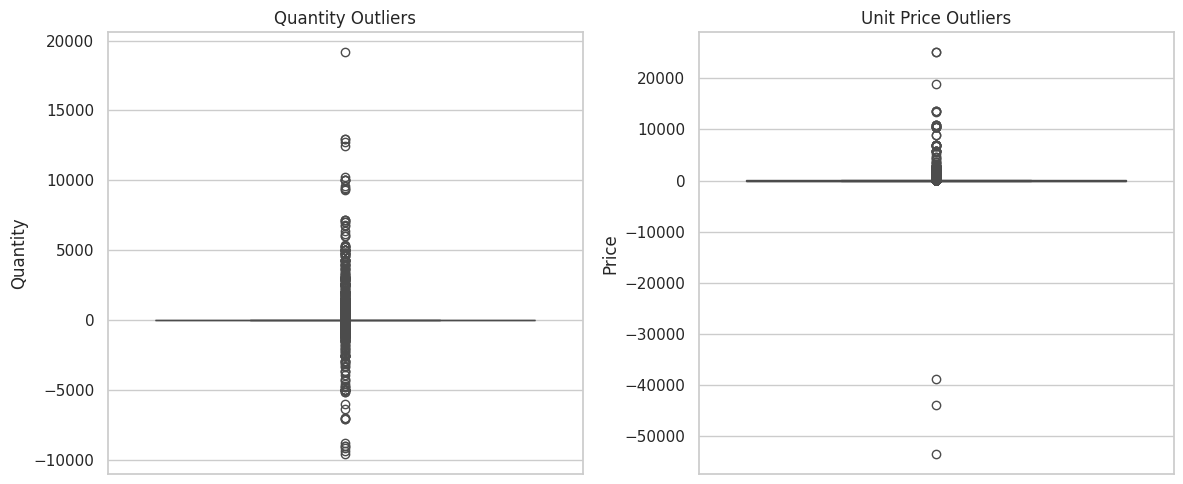

In [19]:
# Outliers Detection

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.boxplot(y=df["Quantity"], ax=axes[0])
axes[0].set_title("Quantity Outliers")

sns.boxplot(y=df["Price"], ax=axes[1])
axes[1].set_title("Unit Price Outliers")

plt.tight_layout()
plt.show()

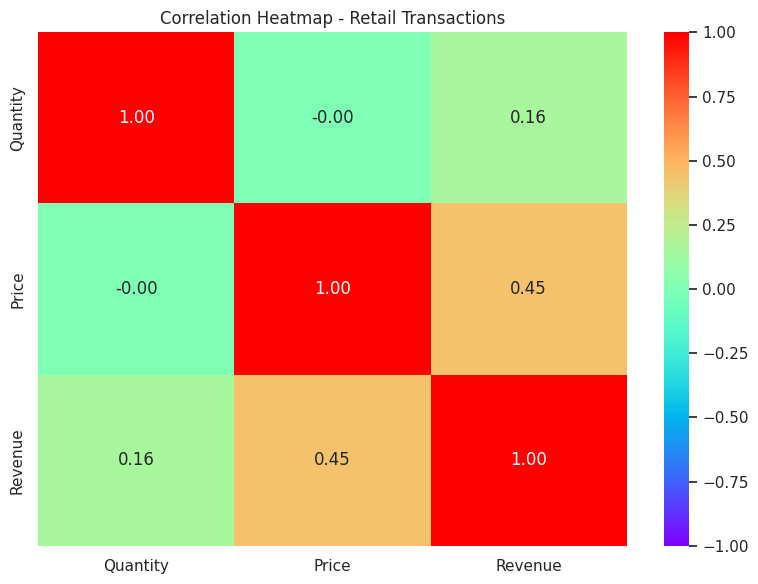

In [20]:
# Correlation heatmap

df["Revenue"] = df["Quantity"] * df["Price"]

num_df = df[
    ["Quantity", "Price", "Revenue"]
].copy()

correlation_matrix = num_df.corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="rainbow",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap - Retail Transactions")
plt.tight_layout()
plt.show()

In [21]:
# Sales analysis

In [22]:
# Calculate transaction revenue

sales_df = df[
    (df["Quantity"] > 0) &
    (df["Price"] > 0) &
    (~df["Invoice"].astype(str).str.startswith("C"))
].copy()

print("Original records:", len(df))
print("Positive-sales records:", len(sales_df))

Original records: 525461
Positive-sales records: 511565


In [23]:
# Calculate key KPIs

total_revenue = sales_df["Revenue"].sum()
total_orders = sales_df["Invoice"].nunique()
total_products = sales_df["StockCode"].nunique()
total_customers = sales_df["Customer ID"].nunique()
total_units = sales_df["Quantity"].sum()

print("Total Revenue:", round(total_revenue, 2))
print("Total Orders:", total_orders)
print("Unique Products:", total_products)
print("Identified Customers:", total_customers)
print("Total Units Sold:", total_units)

Total Revenue: 10305892.02
Total Orders: 20951
Unique Products: 4251
Identified Customers: 4312
Total Units Sold: 5831928


In [24]:
# Analyze duplicate records

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)
print(
    "Duplicate percentage:",
    round((duplicate_count / len(df)) * 100, 2),
    "%"
)

Total duplicate rows: 6865
Duplicate percentage: 1.31 %


In [25]:
# Inspect duplicate records

# Display a few duplicate rows for inspection
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows involved in duplicates:", len(duplicate_rows))
display(duplicate_rows.head(10))

Rows involved in duplicates: 13283


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,12/1/2009 11:34,0.65,16329.0,United Kingdom,7.80
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,12/1/2009 11:34,0.85,16329.0,United Kingdom,5.10
371,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,12/1/2009 11:34,1.95,16329.0,United Kingdom,1.95
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,12/1/2009 11:34,0.85,16329.0,United Kingdom,5.10
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,12/1/2009 11:34,0.65,16329.0,United Kingdom,7.80
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75


In [26]:
# Check exact duplicate rows

# Count exact duplicate rows
exact_duplicates = df.duplicated().sum()

print("Original dataset shape:", df.shape)
print("Exact duplicate rows:", exact_duplicates)

# Preview exact duplicates
display(
    df[df.duplicated(keep=False)]
    .sort_values(["Invoice", "StockCode", "InvoiceDate"])
    .head(20)
)

Original dataset shape: (525461, 9)
Exact duplicate rows: 6865


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,12/1/2009 11:34,1.95,16329.0,United Kingdom,1.95
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,12/1/2009 11:34,1.95,16329.0,United Kingdom,1.95
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
371,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
394,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom,3.75
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,12/1/2009 11:34,0.85,16329.0,United Kingdom,5.10


In [27]:
# Remove exact duplicates

# Create a cleaned dataset
df_clean = df.drop_duplicates().copy()

print("Shape before removing duplicates:", df.shape)
print("Shape after removing duplicates:", df_clean.shape)
print("Rows removed:", len(df) - len(df_clean))

Shape before removing duplicates: (525461, 9)
Shape after removing duplicates: (518596, 9)
Rows removed: 6865


In [28]:
# Date and Time Analysis

In [29]:
# Convert InvoiceDate to datetime

# Convert InvoiceDate to datetime format
df_clean["InvoiceDate"] = pd.to_datetime(
    df_clean["InvoiceDate"],
    errors="coerce"
)

# Check the data type
print(df_clean["InvoiceDate"].dtype)

# Check for invalid dates
print("Missing or invalid dates:", df_clean["InvoiceDate"].isna().sum())

# Display sample records
display(df_clean[["Invoice", "InvoiceDate"]].head())

datetime64[ns]
Missing or invalid dates: 0


,Invoice,InvoiceDate
0,489434,2009-12-01 07:45:00
1,489434,2009-12-01 07:45:00
2,489434,2009-12-01 07:45:00
3,489434,2009-12-01 07:45:00
4,489434,2009-12-01 07:45:00


In [30]:
# Extract date-related features

# Extract date and time features
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Day"] = df_clean["InvoiceDate"].dt.day
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

# Check the new columns
display(
    df_clean[
        ["InvoiceDate", "Year", "Month", "Day", "DayOfWeek", "Hour"]
    ].head()
)


,InvoiceDate,Year,Month,Day,DayOfWeek,Hour
0,2009-12-01 07:45:00,2009,12,1,Tuesday,7
1,2009-12-01 07:45:00,2009,12,1,Tuesday,7
2,2009-12-01 07:45:00,2009,12,1,Tuesday,7
3,2009-12-01 07:45:00,2009,12,1,Tuesday,7
4,2009-12-01 07:45:00,2009,12,1,Tuesday,7


In [31]:
# Extract date and time features

# Extract date and time features
df_clean["Year"] = df_clean["InvoiceDate"].dt.year
df_clean["Month"] = df_clean["InvoiceDate"].dt.month
df_clean["Day"] = df_clean["InvoiceDate"].dt.day
df_clean["DayOfWeek"] = df_clean["InvoiceDate"].dt.day_name()
df_clean["Hour"] = df_clean["InvoiceDate"].dt.hour

# Display the new features
display(
    df_clean[
        ["InvoiceDate", "Year", "Month", "Day", "DayOfWeek", "Hour"]
    ].head()
)

,InvoiceDate,Year,Month,Day,DayOfWeek,Hour
0,2009-12-01 07:45:00,2009,12,1,Tuesday,7
1,2009-12-01 07:45:00,2009,12,1,Tuesday,7
2,2009-12-01 07:45:00,2009,12,1,Tuesday,7
3,2009-12-01 07:45:00,2009,12,1,Tuesday,7
4,2009-12-01 07:45:00,2009,12,1,Tuesday,7


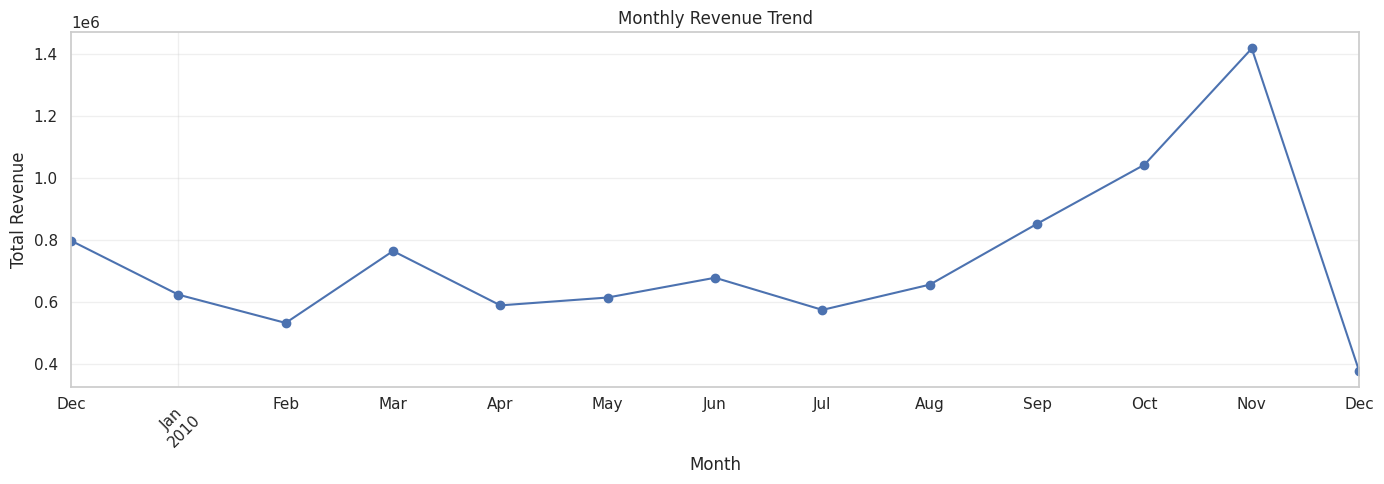

,Total Revenue
YearMonth,
2009-12,796648.500
2010-01,622479.502
2010-02,531265.366
2010-03,763247.241
2010-04,587926.692
2010-05,613270.720
2010-06,677073.870
2010-07,573333.690
2010-08,654774.390


In [32]:
# Analyze monthly revenue trends

# Create a monthly period
df_clean["YearMonth"] = df_clean["InvoiceDate"].dt.to_period("M")

# Calculate monthly revenue
monthly_revenue = (
    df_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .sort_index()
)

# Plot monthly revenue
plt.figure(figsize=(14, 5))
monthly_revenue.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# Display monthly values
display(monthly_revenue.to_frame("Total Revenue"))

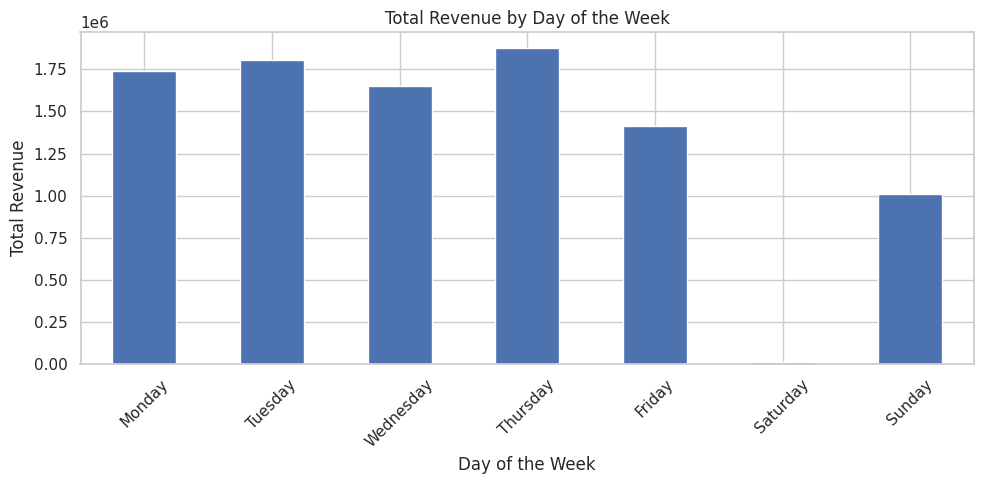

,Total Revenue
DayOfWeek,
Monday,1741937.135
Tuesday,1803586.681
Wednesday,1650843.483
Thursday,1876397.832
Friday,1411860.002
Saturday,9803.050
Sunday,1011347.381


In [33]:
# Analyze sales by day of the week

# Calculate revenue by day of the week
weekday_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]

weekday_revenue = (
    df_clean.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(weekday_order)
)

# Plot weekday revenue
plt.figure(figsize=(10, 5))
weekday_revenue.plot(kind="bar")

plt.title("Total Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(weekday_revenue.to_frame("Total Revenue"))

# key findings

Thursday has the highest recorded revenue.

Saturday has exceptionally low recorded revenue compared with the other days.

This could reflect the retailer's operating schedule or the data's coverage, so we shouldn't assume Saturday is normally a poor sales day without further investigation.

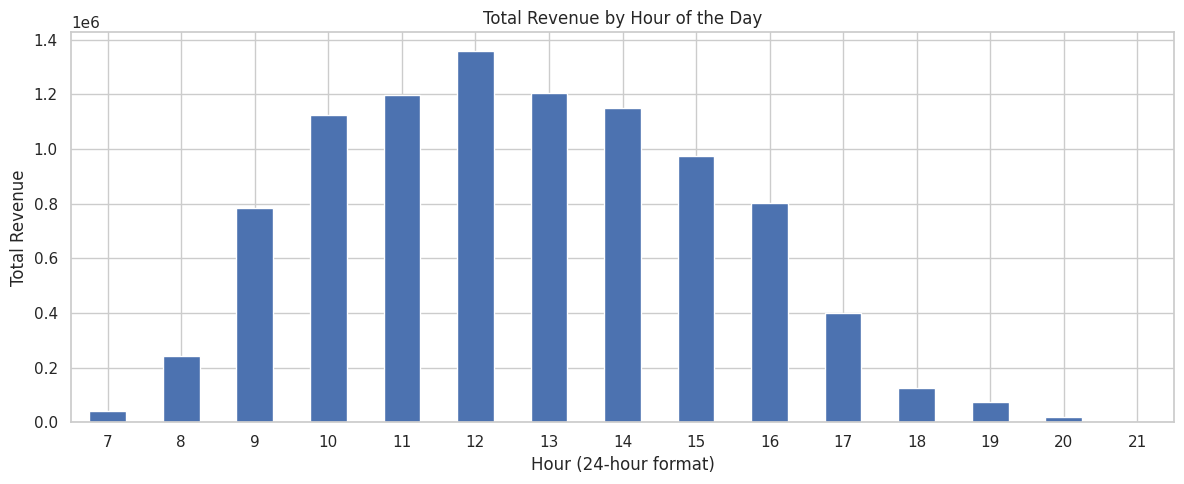

,Total Revenue
Hour,
7,42931.900
8,242648.060
9,783033.090
10,1125776.552
11,1199269.083
12,1359520.731
13,1207005.464
14,1150765.240
15,975498.912


In [34]:
# Analyze revenue by hour

# Calculate revenue by hour
hourly_revenue = (
    df_clean.groupby("Hour")["Revenue"]
    .sum()
    .sort_index()
)

# Plot hourly revenue
plt.figure(figsize=(12, 5))
hourly_revenue.plot(kind="bar")

plt.title("Total Revenue by Hour of the Day")
plt.xlabel("Hour (24-hour format)")
plt.ylabel("Total Revenue")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Display hourly revenue
display(hourly_revenue.to_frame("Total Revenue"))

# Interpret revenue by hour
- Peak hour: 12:00 PM — revenue of approximately 1,359,520.731.
- Strong sales period: 10:00 AM–2:00 PM — these hours contribute the highest recorded revenue.
- Lower activity: Revenue declines after 3:00 PM and is very low after 6:00 PM.
- 21:00 (9 PM): Revenue is slightly negative, at -4.950, which may be related to a return or cancellation

,Total Revenue
Country,
United Kingdom,8161692.763
EIRE,352235.680
Netherlands,263861.760
Germany,195920.421
France,130661.550
Sweden,51190.110
Denmark,46972.950
Switzerland,43343.410
Spain,37052.130


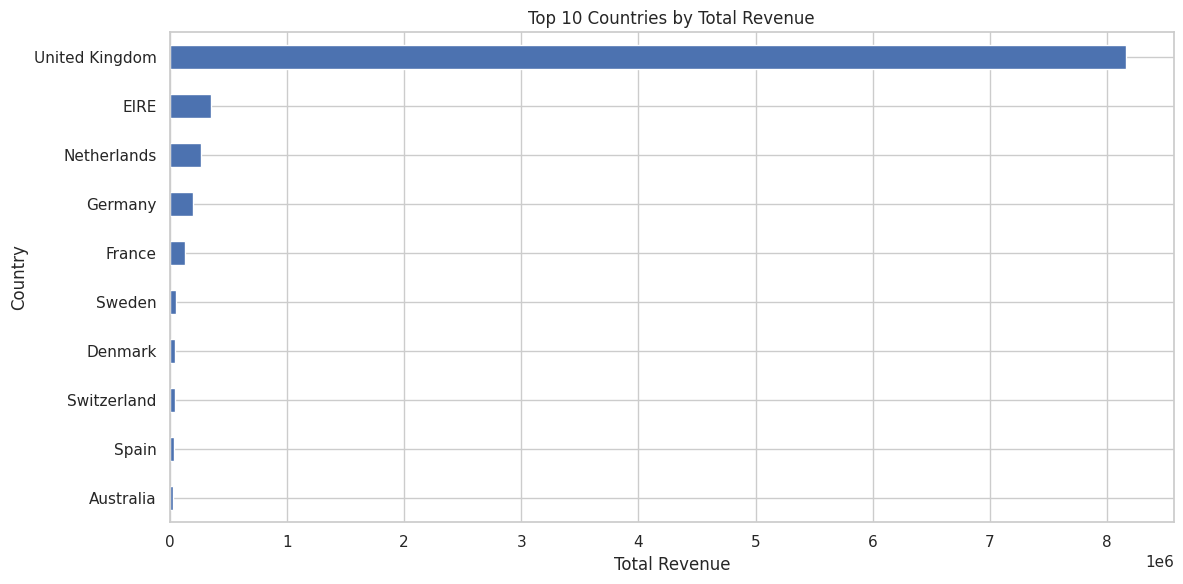

In [35]:
# Analyze revenue by country

# Calculate revenue by country
country_revenue = (
    df_clean.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display the top 10 countries
display(country_revenue.head(10).to_frame("Total Revenue"))

# Plot the top 10 countries
plt.figure(figsize=(12, 6))
country_revenue.head(10).sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Total Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

Interpret country-wise revenue
- United Kingdom: 8,161,692.763 — the highest recorded revenue by a large margin.
- EIRE: 352,235.680 — the second-highest market.
- Netherlands: 263,861.760 — the third-highest market.
- Germany and France are also among the top five markets.

**Business insight:** RetailPulse could prioritize understanding UK customer purchasing patterns while analyzing international markets separately to identify growth opportunities. These figures reflect recorded revenue, including any negative transaction amounts.

In [36]:
# Analyze top-selling products

# Group by product and calculate total quantity and revenue
product_analysis = (
    df_clean.groupby(["StockCode", "Description"], dropna=False)
    .agg(
        Total_Quantity=("Quantity", "sum"),
        Total_Revenue=("Revenue", "sum"),
        Transaction_Lines=("Invoice", "count")
    )
    .sort_values("Total_Revenue", ascending=False)
)

# Display the top 10 products by revenue
display(product_analysis.head(10))

,,Total_Quantity,Total_Revenue,Transaction_Lines
StockCode,Description,,,
22423,REGENCY CAKESTAND 3 TIER,13080,162885.71,2202
85123A,WHITE HANGING HEART T-LIGHT HOLDER,57327,155540.37,3469
DOT,DOTCOM POSTAGE,731,116401.99,735
84879,ASSORTED COLOUR BIRD ORNAMENT,44805,72251.32,1443
22086,PAPER CHAIN KIT 50'S CHRISTMAS,17062,57808.25,991
85099B,JUMBO BAG RED RETROSPOT,30249,54217.92,1276
47566,PARTY BUNTING,10084,49626.92,1034
84347,ROTATING SILVER ANGELS T-LIGHT HLDR,13663,47641.89,362
POST,POSTAGE,2154,46092.36,862


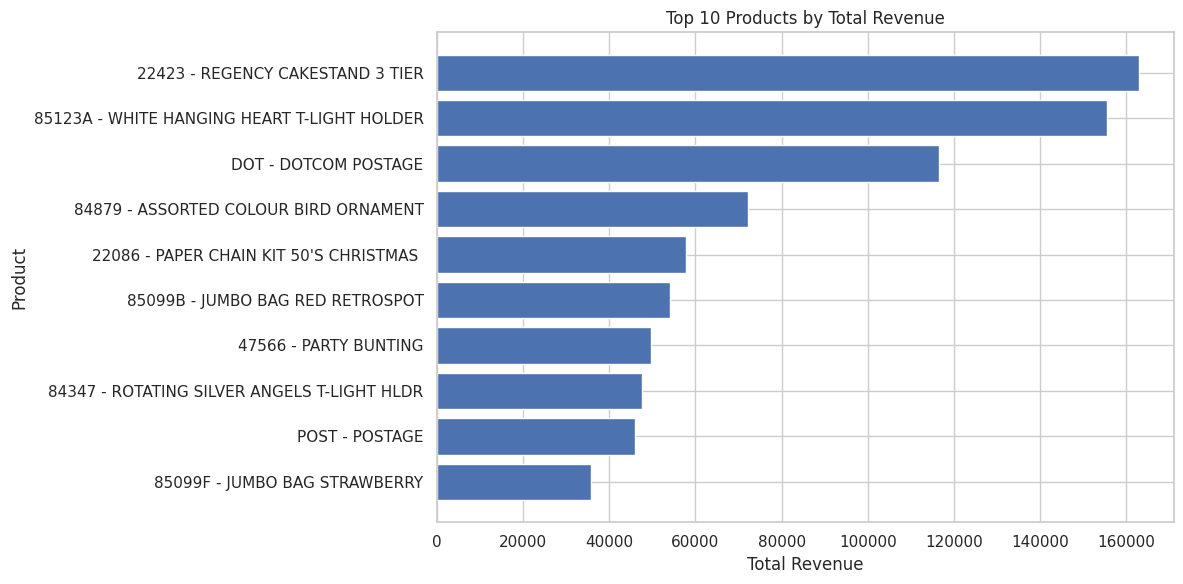

In [37]:
# Visualize the top 10 products

top_products = product_analysis.head(10).reset_index()

# Create readable product labels
top_products["Product"] = (
    top_products["StockCode"].astype(str)
    + " - "
    + top_products["Description"].fillna("Unknown")
)

plt.figure(figsize=(12, 6))
plt.barh(
    top_products["Product"][::-1],
    top_products["Total_Revenue"][::-1]
)

plt.title("Top 10 Products by Total Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

**Key findings**
- Highest revenue product: Regency Cakestand 3 Tier — 162,885.71.
- Second-highest revenue: White Hanging Heart T-Light Holder — 155,540.37.
- Highest quantity sold: White Hanging Heart T-Light Holder — 57,327 units.
- DOTCOM POSTAGE and POSTAGE appear among the top revenue entries, but these are service/postage codes rather than ordinary merchandise. You may want to analyze them separately from physical products.

**Business insight:** The cake stand generates the most revenue among the listed entries, while the hanging heart holder has the highest total quantity. This illustrates why revenue and quantity sold should be analyzed separately.



In [38]:
# Customer purchasing analysis

# Keep records with a known customer ID
customer_df = df_clean.dropna(subset=["Customer ID"]).copy()

# Aggregate customer purchasing behavior
customer_analysis = (
    customer_df.groupby("Customer ID")
    .agg(
        Total_Spend=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Total_Invoices=("Invoice", "nunique"),
        First_Purchase=("InvoiceDate", "min"),
        Last_Purchase=("InvoiceDate", "max")
    )
    .sort_values("Total_Spend", ascending=False)
)

# Display the top 10 customers by net recorded spend
display(customer_analysis.head(10))

,Total_Spend,Total_Quantity,Total_Invoices,First_Purchase,Last_Purchase
Customer ID,,,,,
18102.0,341776.73,122988,95,2009-12-01 09:24:00,2010-12-09 13:44:00
14646.0,243853.05,168501,87,2009-12-02 16:52:00,2010-11-30 16:28:00
14156.0,183163.55,106883,138,2009-12-01 12:30:00,2010-12-03 11:48:00
14911.0,137710.76,66572,270,2009-12-01 11:41:00,2010-12-09 12:17:00
13694.0,128172.42,123639,105,2009-12-04 15:26:00,2010-12-01 12:12:00
17511.0,83760.60,54901,42,2009-12-02 10:52:00,2010-12-07 12:45:00
15061.0,82162.74,51395,90,2009-12-01 12:18:00,2010-12-07 13:50:00
16684.0,75610.17,51705,34,2009-12-07 12:56:00,2010-11-25 11:04:00
13089.0,55801.73,28422,132,2009-12-02 15:44:00,2010-12-06 14:00:00


Interpret customer analysis
- Top customer: Customer ID 18102 with total spend of 341,776.73 across 95 distinct invoices.
- Second-highest: Customer ID 14646 with 243,853.05 across 87 invoices.
- Most invoices among the displayed top 10: Customer ID 14911, with 270 invoices.
- Business insight: Some customers generate high revenue through frequent purchasing, making customer retention and loyalty analysis valuable.
These are net recorded spend figures, so returns and cancellations may affect the rankings.

# Data cleaning and feature engineering

In [39]:
# Check transaction data quality

print("Total rows:", len(df_clean))
print("Negative quantities:", (df_clean["Quantity"] < 0).sum())
print("Zero quantities:", (df_clean["Quantity"] == 0).sum())
print("Negative prices:", (df_clean["Price"] < 0).sum())
print("Zero prices:", (df_clean["Price"] == 0).sum())

# In this dataset, invoices beginning with C commonly indicate cancellations
cancelled_invoices = (
    df_clean["Invoice"].astype(str).str.startswith("C").sum()
)
print("Rows with cancellation invoice numbers:", cancelled_invoices)

# Check missing values in important columns
display(
    df_clean[
        ["Invoice", "StockCode", "Quantity", "InvoiceDate", "Price", "Country"]
    ].isnull().sum().to_frame("Missing Values")
)

Total rows: 518596
Negative quantities: 12302
Zero quantities: 0
Negative prices: 3
Zero prices: 3681
Rows with cancellation invoice numbers: 10182


,Missing Values
Invoice,0
StockCode,0
Quantity,0
InvoiceDate,0
Price,0
Country,0


In [40]:
# Calculate RFM metrics

# Use the latest transaction date as the reference date
reference_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

# Calculate RFM metrics for identified customers
rfm = (
    customer_df.groupby("Customer ID")
    .agg(
        Recency=("InvoiceDate", lambda x: (reference_date - x.max()).days),
        Frequency=("Invoice", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

display(rfm.head(10))
print("Total customers analyzed:", len(rfm))

,Customer ID,Recency,Frequency,Monetary
0,12346.0,67,15,-51.74
1,12347.0,3,2,1323.32
2,12348.0,74,1,222.16
3,12349.0,43,4,2646.99
4,12351.0,11,1,300.93
5,12352.0,11,2,343.80
6,12353.0,44,1,317.76
7,12355.0,203,1,488.21
8,12356.0,16,3,3560.30
9,12357.0,24,2,12079.99


Total customers analyzed: 4383


In [41]:
# Inspect negative prices and zero-price records

# Inspect records with negative prices
negative_price_rows = df_clean[df_clean["Price"] < 0]

display(negative_price_rows)

# Inspect records with zero prices
zero_price_rows = df_clean[df_clean["Price"] == 0]

display(zero_price_rows.head(10))

print("Negative-price rows:", len(negative_price_rows))
print("Zero-price rows:", len(zero_price_rows))

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Year,Month,Day,DayOfWeek,Hour,YearMonth
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,-53594.36,2010,4,29,Thursday,13,2010-04
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,-44031.79,2010,7,19,Monday,11,2010-07
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,-38925.87,2010,10,20,Wednesday,12,2010-10


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,Year,Month,Day,DayOfWeek,Hour,YearMonth
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,10,2009-12
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,10,2009-12
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,10,2009-12
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,11,2009-12
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,17,2009-12
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,0.0,2009,12,1,Tuesday,17,2009-12
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,17,2009-12
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,-0.0,2009,12,1,Tuesday,18,2009-12
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,0.0,2009,12,2,Wednesday,11,2009-12
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,-0.0,2009,12,2,Wednesday,12,2009-12


Negative-price rows: 3
Zero-price rows: 3681


In [42]:
#Check revenue consistency

# Check whether Revenue matches Quantity * Price
expected_revenue = df_clean["Quantity"] * df_clean["Price"]

mismatch_count = (
    (df_clean["Revenue"] - expected_revenue).abs() > 0.000001
).sum()

print("Revenue calculation mismatches:", mismatch_count)

Revenue calculation mismatches: 0


In [43]:
# Check RFM data quality

# Check RFM data quality
print("Total customers:", len(rfm))
print("\nMissing values:")
print(rfm[["Recency", "Frequency", "Monetary"]].isnull().sum())

print("\nRecency summary:")
display(rfm["Recency"].describe())

print("\nFrequency summary:")
display(rfm["Frequency"].describe())

print("\nMonetary summary:")
display(rfm["Monetary"].describe())

print("\nCustomers with zero or negative monetary values:",
      (rfm["Monetary"] <= 0).sum())



Total customers: 4383

Missing values:
Recency      0
Frequency    0
Monetary     0
dtype: int64

Recency summary:


,Recency
count,4383.000000
mean,91.395163
std,98.176493
min,1.000000
25%,17.000000
50%,52.000000
75%,138.000000
max,374.000000



Frequency summary:


,Frequency
count,4383.000000
mean,5.381474
std,10.051921
min,1.000000
25%,1.000000
50%,3.000000
75%,6.000000
max,270.000000



Monetary summary:


,Monetary
count,4383.000000
mean,1897.069492
std,8516.916415
min,-25111.090000
25%,282.885000
50%,652.450000
75%,1633.615000
max,341776.730000



Customers with zero or negative monetary values: 100


Interpret your RFM results
- Recency: Median is 52 days, meaning half of customers made their most recent recorded purchase within 52 days of the reference date.
- Frequency: Median is 3 invoices, while the maximum is 270.
- Monetary: Median net spend is 652.45, compared with a mean of 1,897.07. This suggests spending is highly skewed toward a smaller number of high-value customers.
- 100 customers have zero or negative net monetary values. These customers need special consideration when interpreting monetary scores.

In [44]:
# Assign RFM scores from 1 to 4

# Create a copy so the original RFM data remains unchanged
rfm_scored = rfm.copy()

# Recency: lower number of days is better
rfm_scored["R_Score"] = pd.qcut(
    rfm_scored["Recency"].rank(method="first"),
    q=4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: higher number of invoices is better
rfm_scored["F_Score"] = pd.qcut(
    rfm_scored["Frequency"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: score only customers with positive net spend
rfm_scored["M_Score"] = pd.NA

positive_spend = rfm_scored["Monetary"] > 0

rfm_scored.loc[positive_spend, "M_Score"] = pd.qcut(
    rfm_scored.loc[positive_spend, "Monetary"].rank(method="first"),
    q=4,
    labels=[1, 2, 3, 4]
).astype(int)

# Create a combined RFM score
rfm_scored["RFM_Score"] = (
    rfm_scored["R_Score"].astype(str)
    + rfm_scored["F_Score"].astype(str)
    + rfm_scored["M_Score"].astype("string").fillna("NA")
)

display(rfm_scored.head(10))

print("\nRFM score distributions:")
print(rfm_scored[["R_Score", "F_Score", "M_Score"]].value_counts(
    dropna=False
).head(10))


,Customer ID,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score
0,12346.0,67,15,-51.74,2,4,<NA>,24NA
1,12347.0,3,2,1323.32,4,2,3,423
2,12348.0,74,1,222.16,2,1,1,211
3,12349.0,43,4,2646.99,3,3,4,334
4,12351.0,11,1,300.93,4,1,1,411
5,12352.0,11,2,343.80,4,2,2,422
6,12353.0,44,1,317.76,3,1,2,312
7,12355.0,203,1,488.21,1,1,2,112
8,12356.0,16,3,3560.30,4,2,4,424
9,12357.0,24,2,12079.99,3,2,4,324



RFM score distributions:
R_Score  F_Score  M_Score
4        4        4.0        466
1        1        1.0        340
3        4        4.0        208
         3        3.0        171
1        2        1.0        156
2        3        3.0        152
         1        1.0        144
4        3        3.0        138
1        1        2.0        129
3        2        2.0        126
Name: count, dtype: int64


In [45]:
#Verify the RFM columns

print("Original RFM columns:")
print(rfm.columns.tolist())
display(rfm.head(3).to_string())

print("\nScored RFM columns:")
print(rfm_scored.columns.tolist())
display(rfm_scored.head(3).to_string())


Original RFM columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary']


'   Customer ID  Recency  Frequency  Monetary\n0      12346.0       67         15    -51.74\n1      12347.0        3          2   1323.32\n2      12348.0       74          1    222.16'


Scored RFM columns:
['Customer ID', 'Recency', 'Frequency', 'Monetary', 'R_Score', 'F_Score', 'M_Score', 'RFM_Score']


'   Customer ID  Recency  Frequency  Monetary  R_Score  F_Score M_Score RFM_Score\n0      12346.0       67         15    -51.74        2        4    <NA>      24NA\n1      12347.0        3          2   1323.32        4        2       3       423\n2      12348.0       74          1    222.16        2        1       1       211'

In [46]:
# Create customer segments

rfm_scored["Customer_Segment"] = "Other Customers"

positive_spend = rfm_scored["Monetary"] > 0

# Handle non-positive net spending first
rfm_scored.loc[
    ~positive_spend,
    "Customer_Segment"
] = "Non-positive Net Spend"

# Identify at-risk customers
at_risk = (
    positive_spend &
    (rfm_scored["R_Score"] <= 2) &
    (rfm_scored["F_Score"] >= 3)
)

rfm_scored.loc[
    at_risk,
    "Customer_Segment"
] = "At Risk"

# Identify loyal customers, excluding at-risk customers
loyal = (
    positive_spend &
    (rfm_scored["F_Score"] >= 3) &
    ~at_risk
)

rfm_scored.loc[
    loyal,
    "Customer_Segment"
] = "Loyal Customers"

# Champions take priority among the remaining eligible customers
champions = (
    positive_spend &
    (rfm_scored["R_Score"] >= 3) &
    (rfm_scored["F_Score"] >= 3) &
    (rfm_scored["M_Score"] >= 3)
)

rfm_scored.loc[
    champions,
    "Customer_Segment"
] = "Champions"

print(
    rfm_scored[
        [
            "Customer ID",
            "Recency",
            "Frequency",
            "Monetary",
            "R_Score",
            "F_Score",
            "M_Score",
            "RFM_Score",
            "Customer_Segment"
        ]
    ].head(10).to_string(index=False)

)



 Customer ID  Recency  Frequency  Monetary  R_Score  F_Score M_Score RFM_Score       Customer_Segment
     12346.0       67         15    -51.74        2        4    <NA>      24NA Non-positive Net Spend
     12347.0        3          2   1323.32        4        2       3       423        Other Customers
     12348.0       74          1    222.16        2        1       1       211        Other Customers
     12349.0       43          4   2646.99        3        3       4       334              Champions
     12351.0       11          1    300.93        4        1       1       411        Other Customers
     12352.0       11          2    343.80        4        2       2       422        Other Customers
     12353.0       44          1    317.76        3        1       2       312        Other Customers
     12355.0      203          1    488.21        1        1       2       112        Other Customers
     12356.0       16          3   3560.30        4        2       4       424    

In [47]:
print(rfm_scored["Customer_Segment"].value_counts())

Customer_Segment
Other Customers           2109
Champions                 1274
At Risk                    714
Loyal Customers            186
Non-positive Net Spend     100
Name: count, dtype: int64


# Calculate rolling revenue statistics

In [48]:
# Aggregate revenue by day

# Convert invoice dates to datetime if not already converted
df_clean["InvoiceDate"] = pd.to_datetime(df_clean["InvoiceDate"])

# Calculate total revenue for each calendar day
daily_revenue = (
    df_clean
    .set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
)

# Convert the result into a DataFrame
daily_sales = daily_revenue.to_frame(name="Daily_Revenue")

# Display the first few days
display(daily_sales.head(10))

,Daily_Revenue
InvoiceDate,
2009-12-01,53010.76
2009-12-02,62583.66
2009-12-03,68027.59
2009-12-04,40195.80
2009-12-05,9803.05
2009-12-06,24126.58
2009-12-07,44169.88
2009-12-08,43702.14
2009-12-09,40046.12


In [49]:
# Calculate rolling averages

# Convert Series to DataFrame only if it is not already a DataFrame
if isinstance(daily_revenue, pd.Series):
    daily_revenue = daily_revenue.to_frame(name="Daily_Revenue")
else:
    # If it is already a DataFrame, ensure we rename the column or work with Daily_Revenue
    daily_revenue = daily_revenue.rename(columns={"Revenue": "Daily_Revenue"})

# Calculate moving averages
daily_revenue["Revenue_7D_MA"] = (
    daily_revenue["Daily_Revenue"].rolling(window=7).mean()
)

daily_revenue["Revenue_30D_MA"] = (
    daily_revenue["Daily_Revenue"].rolling(window=30).mean()
)

# Check the result
display(daily_revenue.head(35))

,Daily_Revenue,Revenue_7D_MA,Revenue_30D_MA
InvoiceDate,,,
2009-12-01,53010.76,NaN,NaN
2009-12-02,62583.66,NaN,NaN
2009-12-03,68027.59,NaN,NaN
2009-12-04,40195.80,NaN,NaN
2009-12-05,9803.05,NaN,NaN
2009-12-06,24126.58,NaN,NaN
2009-12-07,44169.88,43131.045714,NaN
2009-12-08,43702.14,41801.242857,NaN
2009-12-09,40046.12,38581.594286,NaN


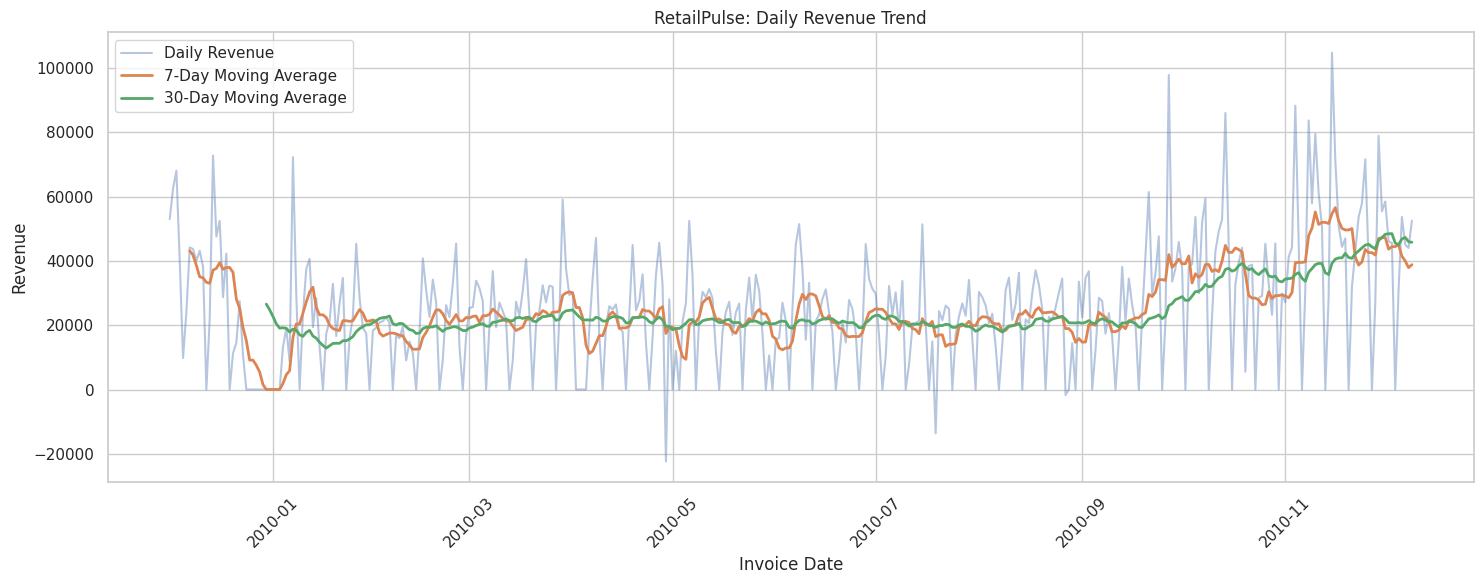

In [50]:
# Plot daily revenue and its rolling averages

plt.figure(figsize=(15, 6))

plt.plot(
    daily_revenue.index,
    daily_revenue["Daily_Revenue"],
    label="Daily Revenue",
    alpha=0.4
)

plt.plot(
    daily_revenue.index,
    daily_revenue["Revenue_7D_MA"],
    label="7-Day Moving Average",
    linewidth=2
)

plt.plot(
    daily_revenue.index,
    daily_revenue["Revenue_30D_MA"],
    label="30-Day Moving Average",
    linewidth=2
)

plt.title("RetailPulse: Daily Revenue Trend")
plt.xlabel("Invoice Date")
plt.ylabel("Revenue")
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [51]:
# Monthly Revenue Analysis

# Ensure InvoiceDate is in datetime format
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

# Calculate transaction revenue
df["Revenue"] = df["Quantity"] * df["Price"]

# Extract year and month
df["YearMonth"] = df["InvoiceDate"].dt.to_period("M")

# Calculate total revenue for each month
monthly_revenue = df.groupby("YearMonth")["Revenue"].sum()

# Display results
display(monthly_revenue.to_frame("Monthly_Revenue"))

,Monthly_Revenue
YearMonth,
2009-12,799847.110
2010-01,624032.892
2010-02,533091.426
2010-03,765848.761
2010-04,590580.432
2010-05,615322.830
2010-06,679786.610
2010-07,575236.360
2010-08,656776.340


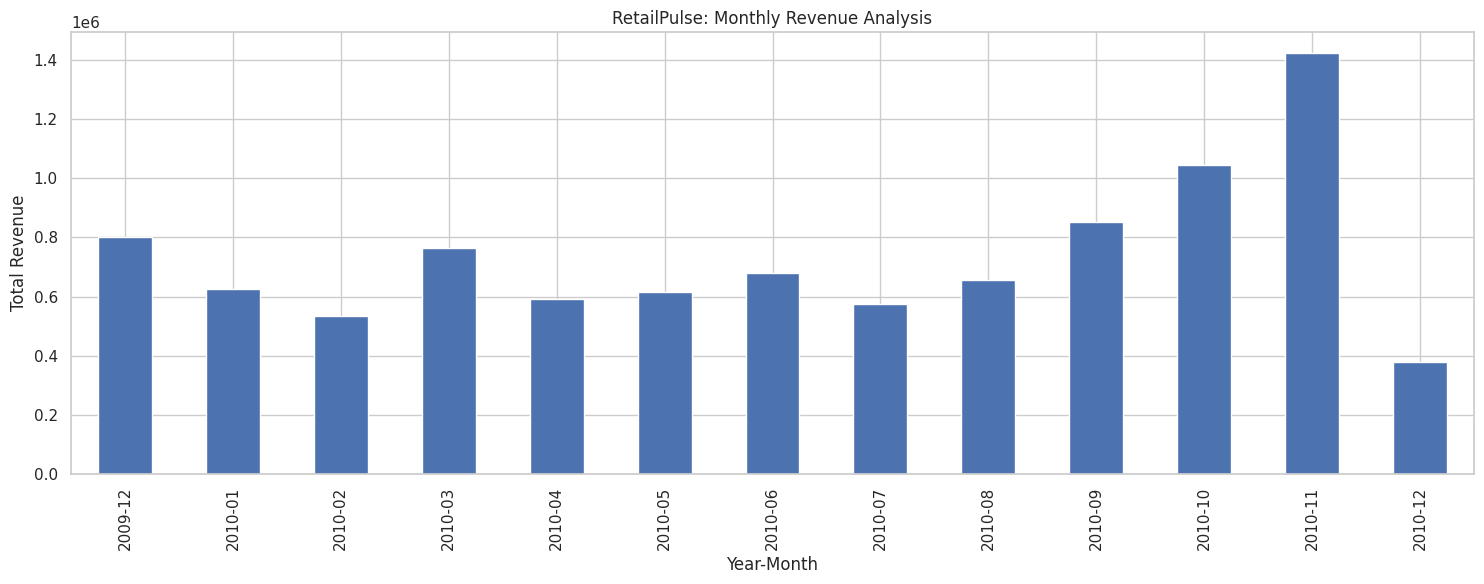

In [52]:
# Visualize monthly revenue

plt.figure(figsize=(15, 6))

monthly_revenue.plot(kind="bar")

plt.title("RetailPulse: Monthly Revenue Analysis")
plt.xlabel("Year-Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [53]:
# Find the highest- and lowest-revenue months

print("Highest Revenue Month:", monthly_revenue.idxmax())
print("Highest Monthly Revenue:", round(monthly_revenue.max(), 2))

print("Lowest Revenue Month:", monthly_revenue.idxmin())
print("Lowest Monthly Revenue:", round(monthly_revenue.min(), 2))

Highest Revenue Month: 2010-11
Highest Monthly Revenue: 1422654.64
Lowest Revenue Month: 2010-12
Lowest Monthly Revenue: 377488.45


In [54]:
# Day-of-Week Revenue Analysis

# Extract day name from InvoiceDate
df["DayOfWeek"] = df["InvoiceDate"].dt.day_name()

# Set weekday order
weekday_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

# Calculate total revenue by day
weekday_revenue = (
    df.groupby("DayOfWeek")["Revenue"]
    .sum()
    .reindex(weekday_order)
)

display(weekday_revenue.to_frame("Total_Revenue"))

,Total_Revenue
DayOfWeek,
Monday,1746606.675
Tuesday,1808690.981
Wednesday,1656091.003
Thursday,1882513.012
Friday,1414972.232
Saturday,9803.050
Sunday,1020807.681


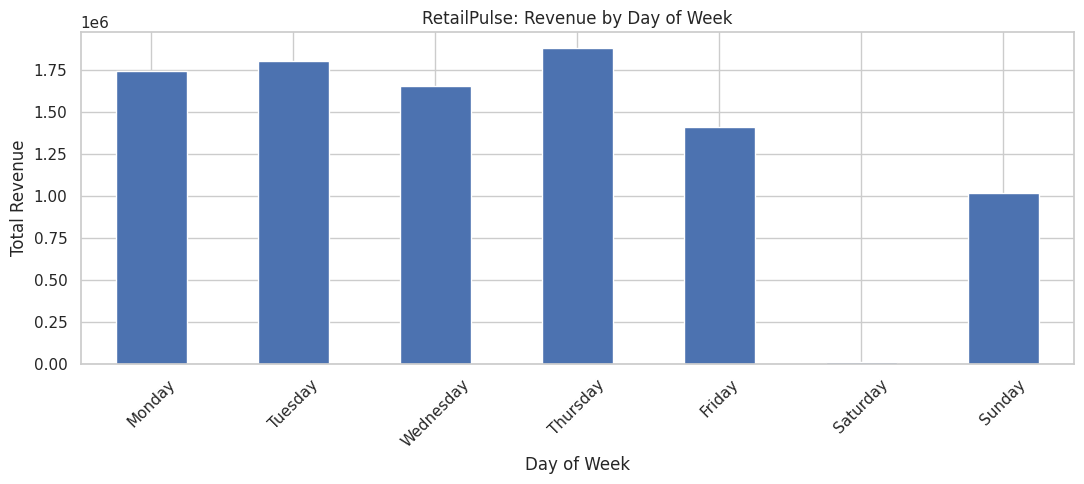

In [55]:
# Visualize weekday revenue

plt.figure(figsize=(11, 5))

weekday_revenue.plot(kind="bar")

plt.title("RetailPulse: Revenue by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [56]:
# Find the best-performing day

print("Highest Revenue Day:", weekday_revenue.idxmax())
print("Highest Revenue:", round(weekday_revenue.max(), 2))

print("Lowest Revenue Day:", weekday_revenue.idxmin())
print("Lowest Revenue:", round(weekday_revenue.min(), 2))

Highest Revenue Day: Thursday
Highest Revenue: 1882513.01
Lowest Revenue Day: Saturday
Lowest Revenue: 9803.05


In [57]:
# Top 10 Products by Revenue

# Remove rows without product descriptions
product_df = df.dropna(subset=["Description"]).copy()

# Calculate revenue by product
product_df["Revenue"] = (
    product_df["Quantity"] * product_df["Price"]
)

product_revenue = (
    product_df.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 products
top_10_products = product_revenue.head(10)

display(top_10_products.to_frame("Total_Revenue"))


,Total_Revenue
Description,
REGENCY CAKESTAND 3 TIER,163051.46
WHITE HANGING HEART T-LIGHT HOLDER,157865.43
DOTCOM POSTAGE,116401.99
ASSORTED COLOUR BIRD ORNAMENT,72454.12
PAPER CHAIN KIT 50'S CHRISTMAS,57870.20
JUMBO BAG RED RETROSPOT,56444.61
PARTY BUNTING,49645.52
ROTATING SILVER ANGELS T-LIGHT HLDR,47672.49
POSTAGE,46092.36


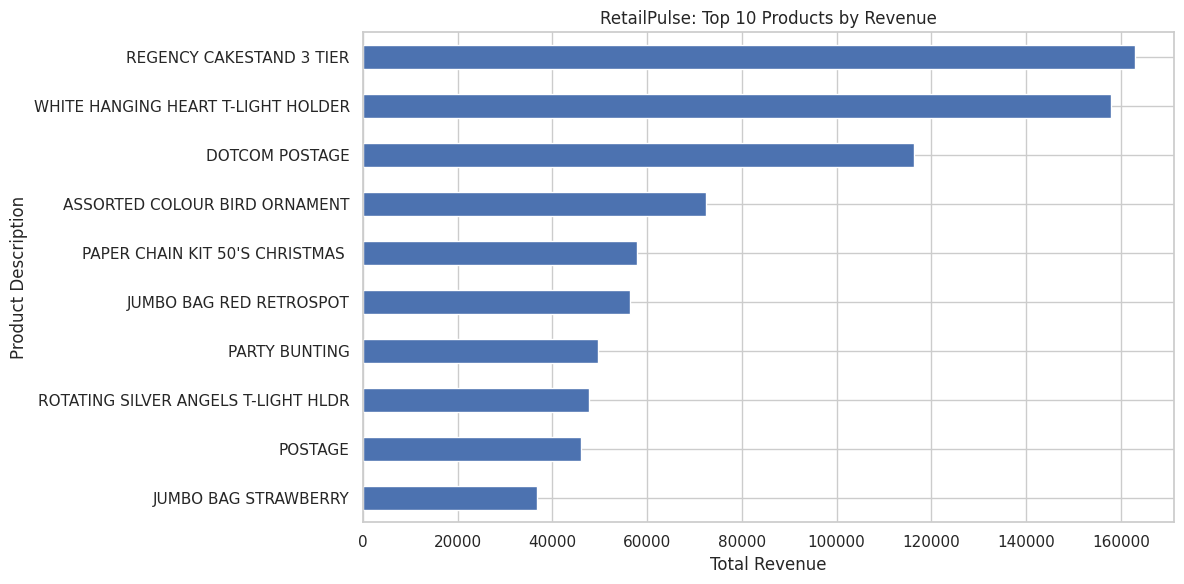

In [58]:
# Visualize the top 10 products

plt.figure(figsize=(12, 6))

top_10_products.sort_values().plot(kind="barh")

plt.title("RetailPulse: Top 10 Products by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Product Description")
plt.tight_layout()
plt.show()

In [59]:
# Top 10 Customers by Revenue

# Remove transactions without Customer ID
customer_df = df.dropna(subset=["Customer ID"]).copy()

# Calculate transaction revenue
customer_df["Revenue"] = (
    customer_df["Quantity"] * customer_df["Price"]
)

# Calculate total revenue by customer
customer_revenue = (
    customer_df.groupby("Customer ID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 customers
top_10_customers = customer_revenue.head(10)

display(top_10_customers.to_frame("Total_Revenue"))

,Total_Revenue
Customer ID,
18102.0,341776.73
14646.0,243853.05
14156.0,183180.55
14911.0,137675.91
13694.0,128172.42
17511.0,83760.60
15061.0,82162.74
16684.0,75610.17
13089.0,55828.31


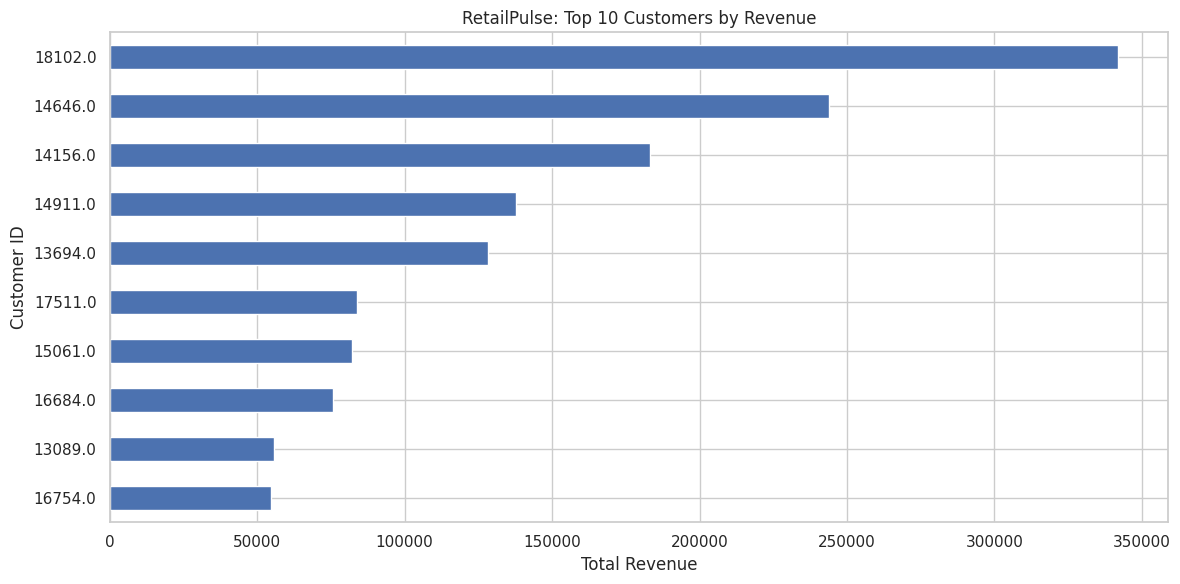

In [60]:
# Visualize the top 10 customers

plt.figure(figsize=(12, 6))

top_10_customers.sort_values().plot(kind="barh")

plt.title("RetailPulse: Top 10 Customers by Revenue")
plt.xlabel("Total Revenue")
plt.ylabel("Customer ID")
plt.tight_layout()
plt.show()

# Great Expectations data validation

In [61]:
%pip install great_expectations

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 49.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.2/49.2 kB 4.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 118.1/118.1 kB 8.1 MB/s eta 0:00:00


In [62]:
import great_expectations as gx

print("Great Expectations version:", gx.__version__)

Great Expectations version: 1.24.1


In [63]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (525461, 11)

Column names:
['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country', 'Revenue', 'YearMonth', 'DayOfWeek']

Data types:
Invoice                object
StockCode              object
Description            object
Quantity                int64
InvoiceDate    datetime64[ns]
Price                 float64
Customer ID           float64
Country                object
Revenue               float64
YearMonth           period[M]
DayOfWeek              object
dtype: object

Missing values:
Invoice             0
StockCode           0
Description      2928
Quantity            0
InvoiceDate         0
Price               0
Customer ID    107927
Country             0
Revenue             0
YearMonth           0
DayOfWeek           0
dtype: int64


In [64]:
# Create a Great Expectations validation suite

# Create a Great Expectations context
context = gx.get_context()

# In Great Expectations v1.x, add a pandas data source using the updated syntax
datasource = context.data_sources.add_pandas(name="retailpulse_datasource")

# Create a Data Asset from the cleaned DataFrame
data_asset = datasource.add_dataframe_asset(name="retailpulse_data")

# Get a Batch of data and build a validator
batch_definition = data_asset.add_batch_definition_whole_dataframe(name="all_data")
batch = batch_definition.get_batch(batch_parameters={"dataframe": df_clean.copy()})

validator = context.get_validator(batch=batch)

print("RetailPulse DataFrame connected to Great Expectations using v1.x syntax!")

INFO:great_expectations.data_context.types.base:Created temporary directory '/tmp/tmpkkv4bmw0' for ephemeral docs site


RetailPulse DataFrame connected to Great Expectations using v1.x syntax!


In [65]:
# Define your expectations

# 1. Required fields must not be missing
result_invoice = validator.expect_column_values_to_not_be_null(
    column="Invoice"
)

result_stock = validator.expect_column_values_to_not_be_null(
    column="StockCode"
)

result_date = validator.expect_column_values_to_not_be_null(
    column="InvoiceDate"
)

result_country = validator.expect_column_values_to_not_be_null(
    column="Country"
)

# 2. Quantity should be an integer
result_quantity = validator.expect_column_values_to_be_of_type(
    column="Quantity",
    type_="int64"
)

# 3. Price should be non-negative
result_price = validator.expect_column_values_to_be_between(
    column="Price",
    min_value=0
)

# 4. Revenue should be numeric
result_revenue = validator.expect_column_values_to_be_of_type(
    column="Revenue",
    type_="float64"
)

# 5. Customer IDs may be missing, so measure missingness
result_customer = validator.expect_column_values_to_not_be_null(
    column="Customer ID",
    mostly=0.70
)

print("All initial expectations have been evaluated.")

Calculating Metrics:   0%|          | 0/6 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/6 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/6 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/6 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/1 [00:00<?, ?it/s]

Calculating Metrics:   0%|          | 0/6 [00:00<?, ?it/s]

All initial expectations have been evaluated.


In [66]:
# Display the results

results = {
    "Invoice not null": result_invoice,
    "StockCode not null": result_stock,
    "InvoiceDate not null": result_date,
    "Country not null": result_country,
    "Quantity type": result_quantity,
    "Price non-negative": result_price,
    "Revenue type": result_revenue,
    "Customer ID completeness": result_customer
}

for check_name, result in results.items():
    print(
        f"{check_name}: "
        f"{'PASS' if result.success else 'FAIL'}"
    )

Invoice not null: PASS
StockCode not null: PASS
InvoiceDate not null: PASS
Country not null: PASS
Quantity type: PASS
Price non-negative: FAIL
Revenue type: PASS
Customer ID completeness: PASS


In [67]:
# Investigate negative prices

# Count negative prices
negative_price_count = (df["Price"] < 0).sum()

print("Negative price records:", negative_price_count)

# Inspect the records
negative_price_rows = df.loc[
    df["Price"] < 0,
    ["Invoice", "StockCode", "Description",
     "Quantity", "InvoiceDate", "Price", "Revenue"]
]

display(negative_price_rows.head(20))

Negative price records: 3


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Revenue
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,-38925.87


In [68]:
# Check the impact on revenue

print("Negative prices:", (df["Price"] < 0).sum())
print("Zero prices:", (df["Price"] == 0).sum())
print("Negative quantities:", (df["Quantity"] < 0).sum())
print("Negative revenue:", (df["Revenue"] < 0).sum())

Negative prices: 3
Zero prices: 3687
Negative quantities: 12326
Negative revenue: 10208


In [69]:
# Inspect the 3 negative-price records

# Display all records with negative prices
display(
    df.loc[
        df["Price"] < 0,
        [
            "Invoice",
            "StockCode",
            "Description",
            "Quantity",
            "InvoiceDate",
            "Price",
            "Customer ID",
            "Country",
            "Revenue"
        ]
    ]
)

,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,-38925.87


In [70]:
# Update the validation rule

# Identify bad-debt adjustment records
bad_debt_mask = df["Description"].eq("Adjust bad debt")

# Check negative prices in ordinary transactions
invalid_negative_prices = df.loc[
    (df["Price"] < 0) & ~bad_debt_mask
]

print("Bad-debt adjustment records:", bad_debt_mask.sum())
print("Negative-price records outside adjustments:",
      len(invalid_negative_prices))

# Display any unexpected negative-price records
display(
    invalid_negative_prices[
        ["Invoice", "Description", "Quantity", "Price", "Revenue"]
    ].head(20)
)

Bad-debt adjustment records: 3
Negative-price records outside adjustments: 0


,Invoice,Description,Quantity,Price,Revenue


In [71]:
# Add the revised Great Expectations check

# Require non-negative prices for ordinary transactions
result_price = validator.expect_column_values_to_be_between(
    column="Price",
    min_value=0,
    mostly=1.0
)

Calculating Metrics:   0%|          | 0/8 [00:00<?, ?it/s]

In [72]:
# Validate revenue consistency

# Step 1: Calculate expected revenue
expected_revenue = df["Quantity"] * df["Price"]

# Step 2: Compare calculated revenue with recorded revenue
revenue_mismatch = (
    (df["Revenue"] - expected_revenue).abs() >= 0.000001
)

# Step 3: Display results
print("Total records:", len(df))
print("Revenue mismatches:", revenue_mismatch.sum())

# Step 4: Display mismatched records, if any
display(
    df.loc[
        revenue_mismatch,
        ["Invoice", "Quantity", "Price", "Revenue"]
    ].head(10)
)

Total records: 525461
Revenue mismatches: 0


,Invoice,Quantity,Price,Revenue


In [73]:
# Check the negative-price exception

bad_debt_mask = df["Description"].eq("Adjust bad debt")

print("Total negative-price records:", (df["Price"] < 0).sum())
print(
    "Negative prices outside bad-debt adjustments:",
    ((df["Price"] < 0) & ~bad_debt_mask).sum()
)

Total negative-price records: 3
Negative prices outside bad-debt adjustments: 0


In [74]:
# Calculate expected revenue
expected_revenue = df["Quantity"] * df["Price"]

# Identify mismatches
revenue_mismatch = (
    (df["Revenue"] - expected_revenue).abs() >= 0.000001
)

print("Total records:", len(df))
print("Revenue mismatches:", revenue_mismatch.sum())

display(
    df.loc[
        revenue_mismatch,
        ["Invoice", "Quantity", "Price", "Revenue"]
    ].head(10)
)

Total records: 525461
Revenue mismatches: 0


,Invoice,Quantity,Price,Revenue


In [75]:
# Complete Great Expectations validation

# Check that negative prices occur only for bad-debt adjustments
invalid_negative_prices = df[
    (df["Price"] < 0) &
    (df["Description"] != "Adjust bad debt")
]

print("Invalid negative-price records:", len(invalid_negative_prices))

if len(invalid_negative_prices) == 0:
    print("PASS: All negative prices are valid bad-debt adjustments.")
else:
    print("FAIL: Unexpected negative-price records found.")
    display(invalid_negative_prices.head())

Invalid negative-price records: 0
PASS: All negative prices are valid bad-debt adjustments.


In [76]:
# Validate negative quantities
# Check negative quantities
negative_quantity_records = df[df["Quantity"] < 0]

print("Negative quantity records:", len(negative_quantity_records))

# Inspect some examples
display(
    negative_quantity_records[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "Revenue"]
    ].head(10)
)

Negative quantity records: 12326


,Invoice,StockCode,Description,Quantity,Price,Revenue
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,-35.40
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,-9.90
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,-17.00
181,C489449,21896,POTTING SHED TWINE,-6,2.10,-12.60
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,-35.40
183,C489449,21871,SAVE THE PLANET MUG,-12,1.25,-15.00
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,1.25,-15.00
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,0.85,-20.40
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2.95,-35.40
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,4.25,-12.75


In [77]:
# Check whether negative quantities have negative revenue

# Separate negative-quantity transactions
returns_df = df[df["Quantity"] < 0]

# Count records by revenue sign
print("Negative quantity records:", len(returns_df))

print(
    "Records with negative revenue:",
    (returns_df["Revenue"] < 0).sum()
)

print(
    "Records with zero revenue:",
    (returns_df["Revenue"] == 0).sum()
)

print(
    "Records with positive revenue:",
    (returns_df["Revenue"] > 0).sum()
)

Negative quantity records: 12326
Records with negative revenue: 10205
Records with zero revenue: 2121
Records with positive revenue: 0


In [78]:
# Investigate zero-revenue records

# Negative quantities with zero revenue
zero_revenue_returns = df[
    (df["Quantity"] < 0) &
    (df["Revenue"] == 0)
]

print("Zero-revenue return records:", len(zero_revenue_returns))

print(
    "Records with zero price:",
    (zero_revenue_returns["Price"] == 0).sum()
)

print(
    "Records with non-zero price:",
    (zero_revenue_returns["Price"] != 0).sum()
)

display(
    zero_revenue_returns[
        ["Invoice", "StockCode", "Description",
         "Quantity", "Price", "Revenue"]
    ].head(10)
)

Zero-revenue return records: 2121
Records with zero price: 2121
Records with non-zero price: 0


,Invoice,StockCode,Description,Quantity,Price,Revenue
263,489464,21733,85123a mixed,-96,0.0,-0.0
283,489463,71477,short,-240,0.0,-0.0
284,489467,85123A,21733 mixed,-192,0.0,-0.0
470,489521,21646,NaN,-50,0.0,-0.0
3114,489655,20683,NaN,-44,0.0,-0.0
3162,489660,35956,lost,-1043,0.0,-0.0
3168,489663,35605A,damages,-117,0.0,-0.0
4296,489806,18010,NaN,-770,0.0,-0.0
4538,489820,21133,invcd as 84879?,-720,0.0,-0.0
4566,489821,85049G,NaN,-240,0.0,-0.0


In [79]:
# Validate zero-price records

# Investigate all zero-price records
zero_price_df = df[df["Price"] == 0].copy()

print("Total zero-price records:", len(zero_price_df))

print("\nTop descriptions among zero-price records:")
display(
    zero_price_df["Description"]
    .fillna("Missing Description")
    .value_counts()
    .head(15)
    .to_frame("Record Count")
)

print("\nRevenue distribution for zero-price records:")
display(zero_price_df["Revenue"].describe())

Total zero-price records: 3687

Top descriptions among zero-price records:


,Record Count
Description,
Missing Description,2928
?,45
damages,39
damaged,38
missing,24
checked,8
OWL DOORSTOP,8
POLYESTER FILLER PAD 45x45cm,7
PICNIC BASKET WICKER LARGE,7



Revenue distribution for zero-price records:


,Revenue
count,3687.0
mean,0.0
std,0.0
min,-0.0
25%,-0.0
50%,0.0
75%,-0.0
max,-0.0


In [80]:
# Add a zero-price validation check

# Validate zero-price records
zero_price_mask = df["Price"] == 0

# Revenue should be zero when price is zero
zero_price_revenue_errors = df[
    zero_price_mask & (df["Revenue"].abs() >= 0.000001)
]

print("Zero-price records:", zero_price_mask.sum())
print("Zero-price revenue errors:", len(zero_price_revenue_errors))

if len(zero_price_revenue_errors) == 0:
    print("PASS: All zero-price records have zero revenue.")
else:
    print("FAIL: Some zero-price records have non-zero revenue.")
    display(zero_price_revenue_errors.head())

Zero-price records: 3687
Zero-price revenue errors: 0
PASS: All zero-price records have zero revenue.


In [81]:
# Validate missing values

# Step 1: Check missing values in every column
missing_summary = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (
        df.isnull().sum() / len(df) * 100
    ).round(2)
})

display(
    missing_summary.sort_values(
        by="Missing Count",
        ascending=False
    )
)

,Missing Count,Missing Percentage
Customer ID,107927,20.54
Description,2928,0.56
Invoice,0,0.00
StockCode,0,0.00
Quantity,0,0.00
InvoiceDate,0,0.00
Price,0,0.00
Country,0,0.00
Revenue,0,0.00
YearMonth,0,0.00


In [82]:
# Handle missing values appropriately

# Create a working copy
df_quality = df.copy()

# Fill missing descriptions
df_quality["Description"] = (
    df_quality["Description"]
    .fillna("Unknown Product")
)

# Check missing values after handling Description
print("Missing Description:",
      df_quality["Description"].isna().sum())

print("Missing Customer ID:",
      df_quality["Customer ID"].isna().sum())

print("Original rows:", len(df))
print("Working DataFrame rows:", len(df_quality))

Missing Description: 0
Missing Customer ID: 107927
Original rows: 525461
Working DataFrame rows: 525461


In [83]:
# Check duplicate records
# Step 1: Count fully duplicated rows
duplicate_count = df_quality.duplicated().sum()

print("Total rows:", len(df_quality))
print("Fully duplicated rows:", duplicate_count)

# Step 2: Display examples, if any
if duplicate_count > 0:
    duplicates = df_quality[
        df_quality.duplicated(keep=False)
    ]

    display(duplicates.head(10))
else:
    print("PASS: No fully duplicated rows found.")

Total rows: 525461
Fully duplicated rows: 6865


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,YearMonth,DayOfWeek
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
367,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,7.80,2009-12,Tuesday
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10,2009-12,Tuesday
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95,2009-12,Tuesday
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10,2009-12,Tuesday
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,7.80,2009-12,Tuesday
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday


In [84]:
# Understand the duplicate records

# Identify all rows belonging to duplicate groups
duplicates = df_quality[
    df_quality.duplicated(keep=False)
].sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
)

print("Rows involved in duplicate groups:", len(duplicates))

display(duplicates.head(20))

Rows involved in duplicate groups: 13283


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,YearMonth,DayOfWeek
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95,2009-12,Tuesday
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95,2009-12,Tuesday
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10,2009-12,Tuesday


In [85]:
# Check how many rows would remain after deduplication

# Count rows after removing exact duplicates in a copy
df_deduplicated = df_quality.drop_duplicates().copy()

print("Original row count:", len(df_quality))
print("Rows after deduplication:", len(df_deduplicated))
print("Rows removed:", len(df_quality) - len(df_deduplicated))

Original row count: 525461
Rows after deduplication: 518596
Rows removed: 6865


In [86]:
#Decide whether to remove duplicates

# Display all rows belonging to duplicate groups
duplicates = df_quality[
    df_quality.duplicated(keep=False)
].sort_values(
    by=["Invoice", "StockCode", "InvoiceDate"]
)

print("Rows involved in duplicate groups:", len(duplicates))

display(duplicates.head(20))

Rows involved in duplicate groups: 13283


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country,Revenue,YearMonth,DayOfWeek
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95,2009-12,Tuesday
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,1.95,2009-12,Tuesday
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,3.75,2009-12,Tuesday
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,5.10,2009-12,Tuesday


In [87]:
# Create your cleaned dataset

# Use the deduplicated dataset for further validation
df_clean = df_deduplicated.copy()

print("Rows before deduplication:", len(df_quality))
print("Rows after deduplication:", len(df_clean))
print("Remaining exact duplicates:", df_clean.duplicated().sum())
print("Missing descriptions:", df_clean["Description"].isna().sum())
print("Missing Customer IDs:", df_clean["Customer ID"].isna().sum())

Rows before deduplication: 525461
Rows after deduplication: 518596
Remaining exact duplicates: 0
Missing descriptions: 0
Missing Customer IDs: 107833


In [88]:
# Validate data types
# Inspect data types
display(
    pd.DataFrame({
        "Data Type": df_clean.dtypes.astype(str),
        "Missing Values": df_clean.isnull().sum()
    })
)

,Data Type,Missing Values
Invoice,object,0
StockCode,object,0
Description,object,0
Quantity,int64,0
InvoiceDate,datetime64[ns],0
Price,float64,0
Customer ID,float64,107833
Country,object,0
Revenue,float64,0
YearMonth,period[M],0


In [89]:
# Validate data types and business rules

# Data quality validation summary
checks = {
    "Invoice is not missing": df_clean["Invoice"].notna().all(),
    "StockCode is not missing": df_clean["StockCode"].notna().all(),
    "InvoiceDate is datetime": pd.api.types.is_datetime64_any_dtype(
        df_clean["InvoiceDate"]
    ),
    "Quantity is integer": pd.api.types.is_integer_dtype(
        df_clean["Quantity"]
    ),
    "Price is numeric": pd.api.types.is_numeric_dtype(
        df_clean["Price"]
    ),
    "Revenue is numeric": pd.api.types.is_numeric_dtype(
        df_clean["Revenue"]
    ),
    "Revenue matches Quantity x Price": (
        (df_clean["Revenue"] -
         df_clean["Quantity"] * df_clean["Price"]).abs() < 0.000001
    ).all(),
    "No exact duplicate rows": not df_clean.duplicated().any(),
    "Descriptions are complete": df_clean["Description"].notna().all()
}

validation_report = pd.DataFrame({
    "Check": checks.keys(),
    "Result": [
        "PASS" if result else "FAIL"
        for result in checks.values()
    ]
})

display(validation_report)

,Check,Result
0,Invoice is not missing,PASS
1,StockCode is not missing,PASS
2,InvoiceDate is datetime,PASS
3,Quantity is integer,PASS
4,Price is numeric,PASS
5,Revenue is numeric,PASS
6,Revenue matches Quantity x Price,PASS
7,No exact duplicate rows,PASS
8,Descriptions are complete,PASS


**Customer segmentation using K-Means and DBSCAN**

In [90]:
# Prepare customer features

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)

# Work with customer-level RFM data
cluster_df = rfm.copy()

# Keep customers with valid RFM values
cluster_df = cluster_df.dropna(
    subset=["Recency", "Frequency", "Monetary"]
).copy()

# Transform skewed features
X = cluster_df[["Recency", "Frequency", "Monetary"]].copy()

X["Recency"] = np.log1p(X["Recency"].clip(lower=0))
X["Frequency"] = np.log1p(X["Frequency"].clip(lower=0))

# Signed log transformation preserves negative net spending
X["Monetary"] = (
    np.sign(X["Monetary"])
    * np.log1p(X["Monetary"].abs())
)

# Scale all features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Customers:", len(cluster_df))
print("Features:", X.columns.tolist())
print("Scaled data shape:", X_scaled.shape)

Customers: 4383
Features: ['Recency', 'Frequency', 'Monetary']
Scaled data shape: (4383, 3)


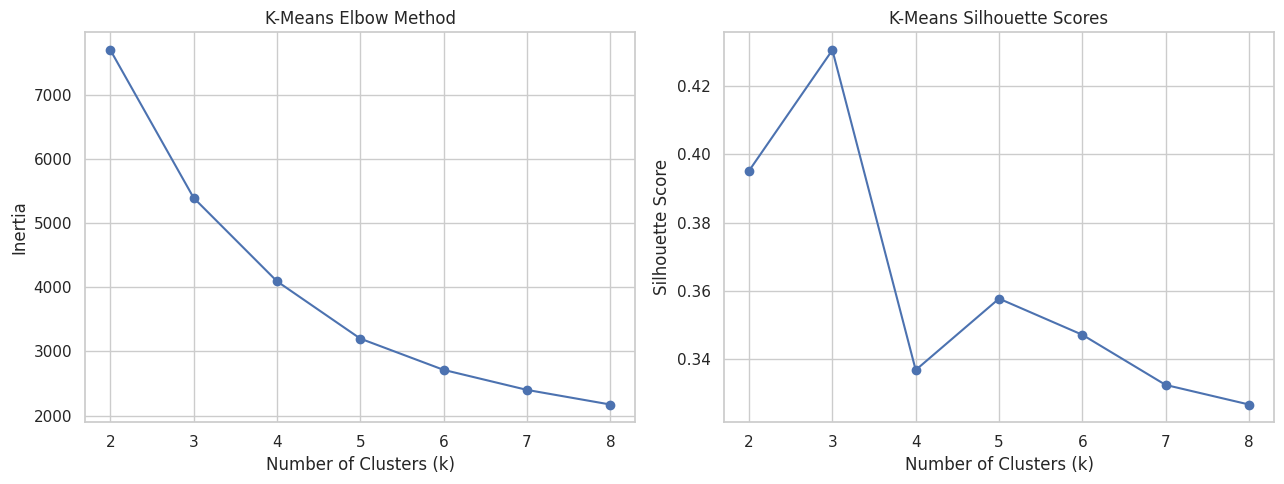

   k    Inertia  Silhouette Score
0  2  7701.8211            0.3952
1  3  5394.9371            0.4307
2  4  4094.2484            0.3367
3  5  3200.1315            0.3577
4  6  2712.7046            0.3471
5  7  2400.4159            0.3323
6  8  2172.3100            0.3266


In [91]:
#Find a suitable number of K-Means clusters

inertias = []
silhouette_scores = []
k_values = range(2, 9)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_scaled)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_scaled, labels)
    )

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].plot(k_values, inertias, marker="o")
axes[0].set_title("K-Means Elbow Method")
axes[0].set_xlabel("Number of Clusters (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_values, silhouette_scores, marker="o")
axes[1].set_title("K-Means Silhouette Scores")
axes[1].set_xlabel("Number of Clusters (k)")
axes[1].set_ylabel("Silhouette Score")

plt.tight_layout()
plt.show()

print(pd.DataFrame({
    "k": list(k_values),
    "Inertia": inertias,
    "Silhouette Score": silhouette_scores
}).round(4))

In [92]:
# Train the final K-Means model

best_k = 4  # Replace with your selected value

kmeans = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=10
)

cluster_df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

print(
    cluster_df["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

display(
    cluster_df.groupby("KMeans_Cluster")[
        ["Recency", "Frequency", "Monetary"]
    ].mean().round(2)
)

KMeans_Cluster
0    1761
1    1630
2     886
3     106
Name: count, dtype: int64


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,42.81,3.77,1141.16
1,177.36,1.63,410.31
2,15.84,15.84,6468.53
3,208.25,2.29,-892.83


In [93]:
# Apply DBSCAN

dbscan = DBSCAN(
    eps=0.5,
    min_samples=10
)

cluster_df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

print("DBSCAN cluster counts:")
print(
    cluster_df["DBSCAN_Cluster"]
    .value_counts()
    .sort_index()
)

noise_count = (
    cluster_df["DBSCAN_Cluster"] == -1
).sum()

print("Noise customers:", noise_count)
print(
    "Noise percentage:",
    round(noise_count / len(cluster_df) * 100, 2),
    "%"
)

DBSCAN cluster counts:
DBSCAN_Cluster
-1     100
 0    3037
 1    1198
 2      48
Name: count, dtype: int64
Noise customers: 100
Noise percentage: 2.28 %


In [94]:
# Evaluate both algorithms

def evaluate_clustering(X_data, labels, algorithm):
    labels = np.asarray(labels)

    # Exclude DBSCAN noise from evaluation
    if algorithm == "DBSCAN":
        valid = labels != -1
        X_eval = X_data[valid]
        labels_eval = labels[valid]
    else:
        X_eval = X_data
        labels_eval = labels

    n_clusters = len(set(labels_eval))
    n_samples = len(labels_eval)

    result = {
        "Algorithm": algorithm,
        "Clusters": n_clusters,
        "Noise Points": int((labels == -1).sum())
                       if algorithm == "DBSCAN" else 0,
        "Silhouette": np.nan,
        "Davies-Bouldin": np.nan,
        "Calinski-Harabasz": np.nan
    }

    if n_clusters >= 2 and n_samples > n_clusters:
        result["Silhouette"] = silhouette_score(
            X_eval, labels_eval
        )
        result["Davies-Bouldin"] = davies_bouldin_score(
            X_eval, labels_eval
        )
        result["Calinski-Harabasz"] = calinski_harabasz_score(
            X_eval, labels_eval
        )

    return result


results = pd.DataFrame([
    evaluate_clustering(
        X_scaled,
        cluster_df["KMeans_Cluster"],
        "K-Means"
    ),
    evaluate_clustering(
        X_scaled,
        cluster_df["DBSCAN_Cluster"],
        "DBSCAN"
    )
])

display(results.round(4))

,Algorithm,Clusters,Noise Points,Silhouette,Davies-Bouldin,Calinski-Harabasz
0,K-Means,4,0,0.3367,0.9164,3228.1762
1,DBSCAN,3,100,0.2668,0.8487,1392.4920


Interpret the clusters for business decisions

In [95]:
kmeans_summary = (
    cluster_df.groupby("KMeans_Cluster")
    .agg(
        Customers=("Recency", "size"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
        Median_Monetary=("Monetary", "median")
    )
    .round(2)
)

kmeans_summary["Customer_Percentage"] = (
    kmeans_summary["Customers"]
    / len(cluster_df) * 100
).round(2)

display(kmeans_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Median_Monetary,Customer_Percentage
KMeans_Cluster,,,,,,
0,1761,42.81,3.77,1141.16,830.18,40.18
1,1630,177.36,1.63,410.31,288.21,37.19
2,886,15.84,15.84,6468.53,2977.20,20.21
3,106,208.25,2.29,-892.83,-52.87,2.42


### Customer Segmentation Using K-Means

K-Means clustering was applied to the customer-level RFM dataset to identify distinct purchasing behavior patterns. Four customer clusters were obtained.

Cluster 0 represented regular customers, accounting for 40.18% of the customer base. Cluster 1 accounted for 37.19% and consisted of customers with relatively high recency and low purchase frequency, making them potential targets for re-engagement campaigns. Cluster 2 represented 20.21% of customers and demonstrated the strongest purchasing behavior, with low recency, high frequency, and high monetary value. These customers are suitable for loyalty and retention initiatives.

Cluster 3 contained 2.42% of customers with negative average net spending. Their transaction histories should be reviewed to understand the effects of refunds, returns, or cancellations.

Overall, K-Means provides actionable customer segments for targeted marketing and retention strategies. Its performance should be compared with DBSCAN using clustering evaluation metrics and business interpretability before selecting the preferred algorithm.


In [96]:
# Compare customer profiles for DBSCAN

dbscan_summary = (
    cluster_df.groupby("DBSCAN_Cluster")
    .agg(
        Customers=("Recency", "size"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean")
    )
    .round(2)
)

dbscan_summary["Customer_Percentage"] = (
    dbscan_summary["Customers"]
    / len(cluster_df) * 100
).round(2)

display(dbscan_summary)

,Customers,Avg_Recency,Avg_Frequency,Avg_Monetary,Customer_Percentage
DBSCAN_Cluster,,,,,
-1,100,98.34,25.82,18285.12,2.28
0,3037,64.25,6.51,2025.28,69.29
1,1198,151.29,1.00,297.99,27.33
2,48,299.56,1.00,-446.05,1.10


### Customer Segmentation Using DBSCAN

DBSCAN was applied to the customer-level RFM dataset to identify groups with similar purchasing behavior and detect customers with unusual patterns. The algorithm identified three clusters and one noise group.

Cluster 0 represented the largest customer segment, accounting for 69.29% of customers. These customers had relatively lower recency and higher purchase frequency than Cluster 1, making them suitable for repeat-purchase and loyalty campaigns. Cluster 1 accounted for 27.33% of customers and showed higher recency and lower purchase frequency, indicating an opportunity for customer re-engagement initiatives.

Cluster 2 contained 1.10% of customers, with high recency and negative average net spending. These customers should be investigated for returns, cancellations, and other adjustments. The remaining 2.28% were classified as noise. Their high average net spending makes them particularly important to inspect before excluding them from business analysis.

Overall, DBSCAN provides useful insights into customer purchasing patterns and highlights unusual customer profiles. Its effectiveness should be evaluated alongside clustering metrics, noise percentage, and the business interpretability of the resulting segments.


# **Time-series data preparation for forecasting**

In [97]:
# Prepare the daily revenue dataset

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"], errors="coerce"
)

df = df.dropna(subset=["InvoiceDate"]).copy()

# Calculate revenue only if it does not already exist
if "Revenue" not in df.columns:
    df["Revenue"] = df["Quantity"] * df["Price"]

# Aggregate revenue by day
daily_revenue = (
    df.set_index("InvoiceDate")["Revenue"]
    .resample("D")
    .sum()
    .asfreq("D", fill_value=0)
)

print("Start date:", daily_revenue.index.min())
print("End date:", daily_revenue.index.max())
print("Number of daily observations:", len(daily_revenue))
print("Missing values:", daily_revenue.isna().sum())

display(daily_revenue.head())

Start date: 2009-12-01 00:00:00
End date: 2010-12-09 00:00:00
Number of daily observations: 374
Missing values: 0


,Revenue
InvoiceDate,
2009-12-01,53173.03
2009-12-02,62763.59
2009-12-03,68093.05
2009-12-04,40346.40
2009-12-05,9803.05


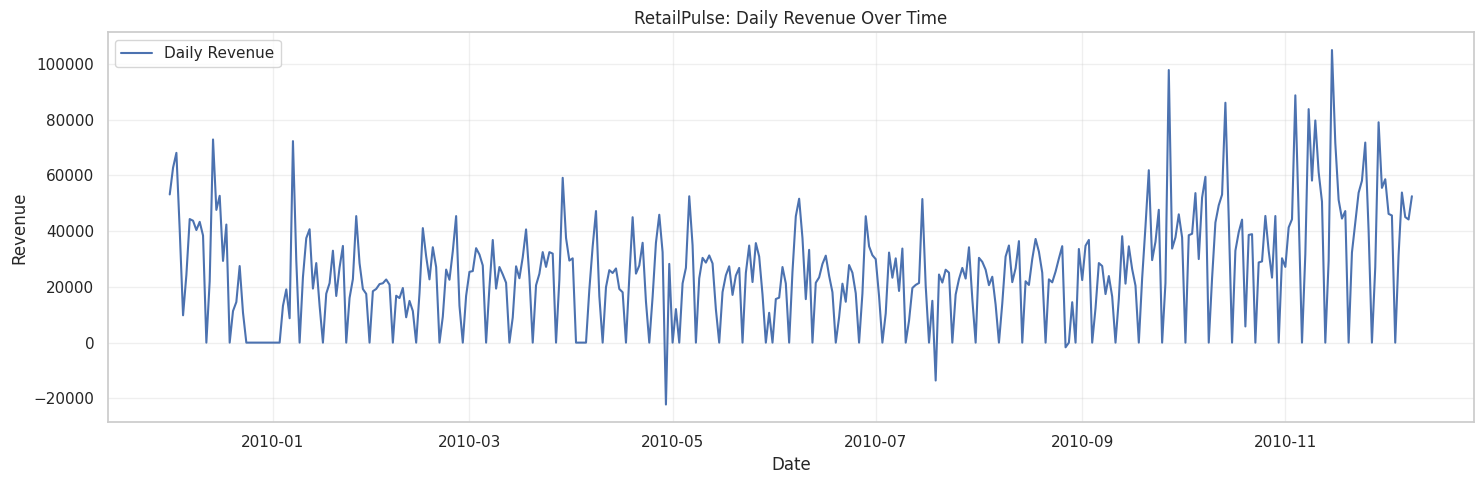

In [98]:
# Visualize the time series

plt.figure(figsize=(15, 5))

plt.plot(
    daily_revenue.index,
    daily_revenue.values,
    label="Daily Revenue"
)

plt.title("RetailPulse: Daily Revenue Over Time")
plt.xlabel("Date")
plt.ylabel("Revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [99]:
# Check stationarity using the ADF test

from statsmodels.tsa.stattools import adfuller

adf_result = adfuller(daily_revenue.dropna())

print("ADF Statistic:", adf_result[0])
print("p-value:", adf_result[1])
print("Critical Values:", adf_result[4])

if adf_result[1] < 0.05:
    print("Conclusion: Reject H0; evidence supports stationarity.")
else:
    print("Conclusion: Fail to reject H0; non-stationarity remains plausible.")

ADF Statistic: -2.6175955788266743
p-value: 0.08941487608548743
Critical Values: {'1%': np.float64(-3.4486972813047574), '5%': np.float64(-2.8696246923288418), '10%': np.float64(-2.571077032068342)}
Conclusion: Fail to reject H0; non-stationarity remains plausible.


In [100]:
# Confirm with the KPSS test

from statsmodels.tsa.stattools import kpss

kpss_stat, kpss_pvalue, _, kpss_critical = kpss(
    daily_revenue.dropna(),
    regression="c",
    nlags="auto"
)

print("KPSS Statistic:", kpss_stat)
print("p-value:", kpss_pvalue)
print("Critical Values:", kpss_critical)

if kpss_pvalue < 0.05:
    print("Conclusion: Reject stationarity.")
else:
    print("Conclusion: Insufficient evidence to reject stationarity.")

  kpss_stat, kpss_pvalue, _, kpss_critical = kpss(



KPSS Statistic: 1.4714721852454586
p-value: 0.01
Critical Values: {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}
Conclusion: Reject stationarity.


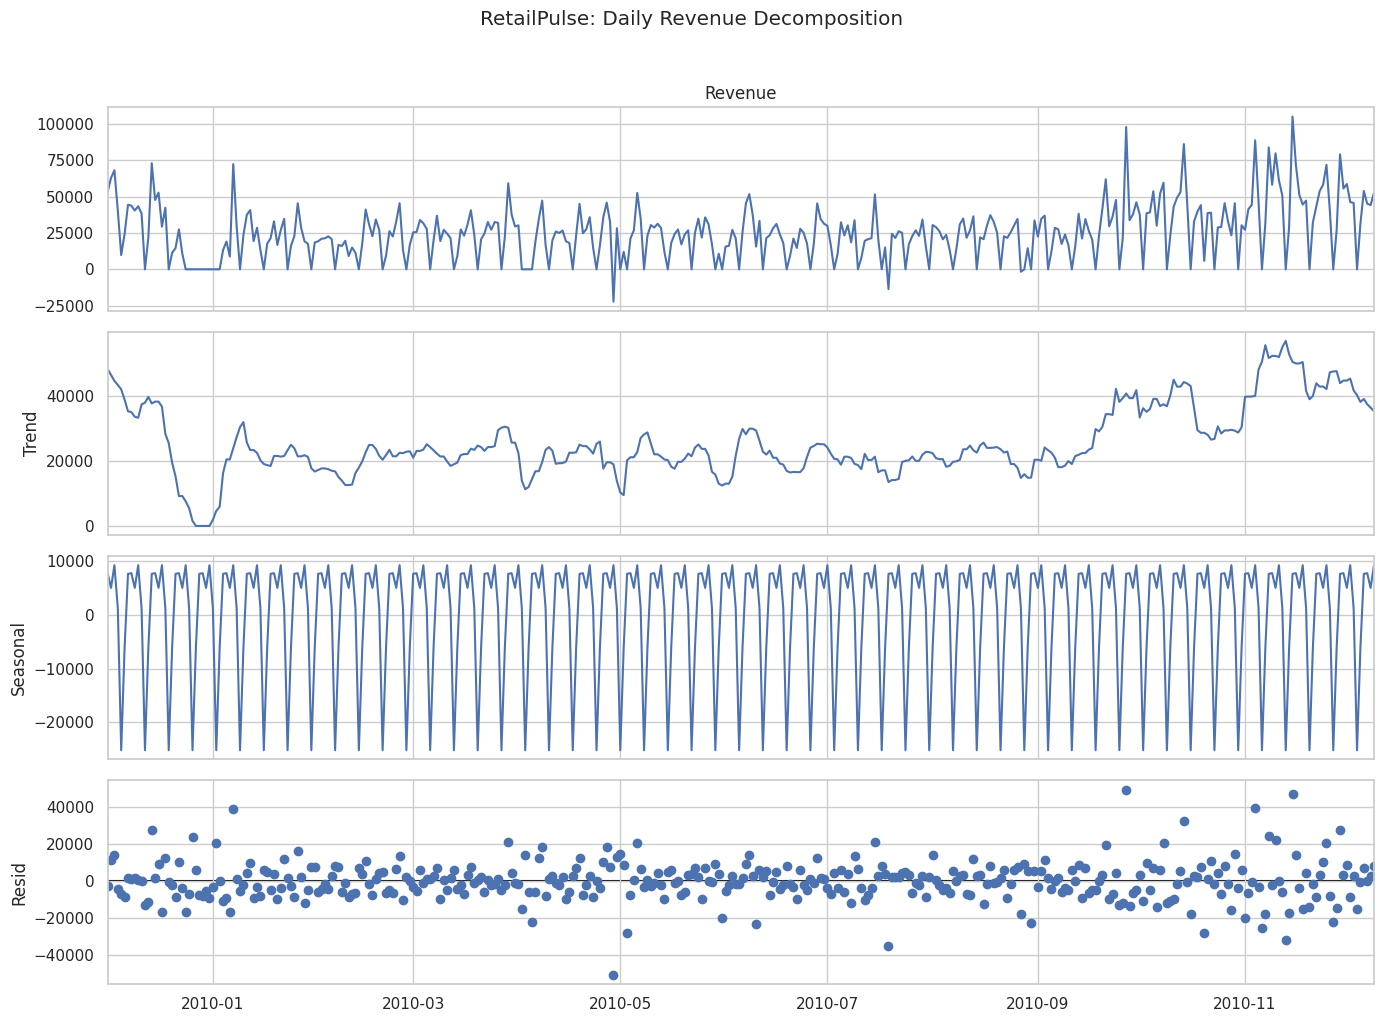

In [101]:
# Decompose the time series

from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    daily_revenue,
    model="additive",
    period=7,
    extrapolate_trend="freq"
)

fig = decomposition.plot()
fig.set_size_inches(14, 10)
fig.suptitle(
    "RetailPulse: Daily Revenue Decomposition",
    y=1.02
)
plt.tight_layout()
plt.show()

In [102]:
# Prepare the forecasting train-test split

split_idx = int(len(daily_revenue) * 0.80)

train = daily_revenue.iloc[:split_idx]
test = daily_revenue.iloc[split_idx:]

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train.index.max())
print("Testing starts:", test.index.min())

Training observations: 299
Testing observations: 75
Training ends: 2010-09-25 00:00:00
Testing starts: 2010-09-26 00:00:00


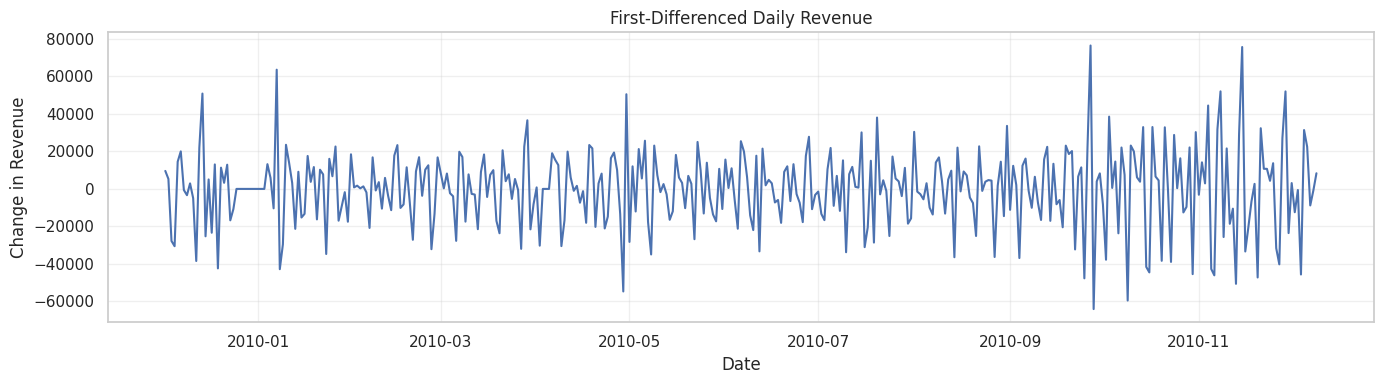

ADF p-value after differencing: 9.459014602035318e-16
KPSS p-value after differencing: 0.04166666666666122


In [103]:
daily_revenue_diff = daily_revenue.diff().dropna()

plt.figure(figsize=(14, 4))
plt.plot(daily_revenue_diff.index, daily_revenue_diff.values)
plt.title("First-Differenced Daily Revenue")
plt.xlabel("Date")
plt.ylabel("Change in Revenue")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

print("ADF p-value after differencing:",
      adfuller(daily_revenue_diff)[1])
print("KPSS p-value after differencing:",
      kpss(daily_revenue_diff, regression="c", nlags="auto")[1])

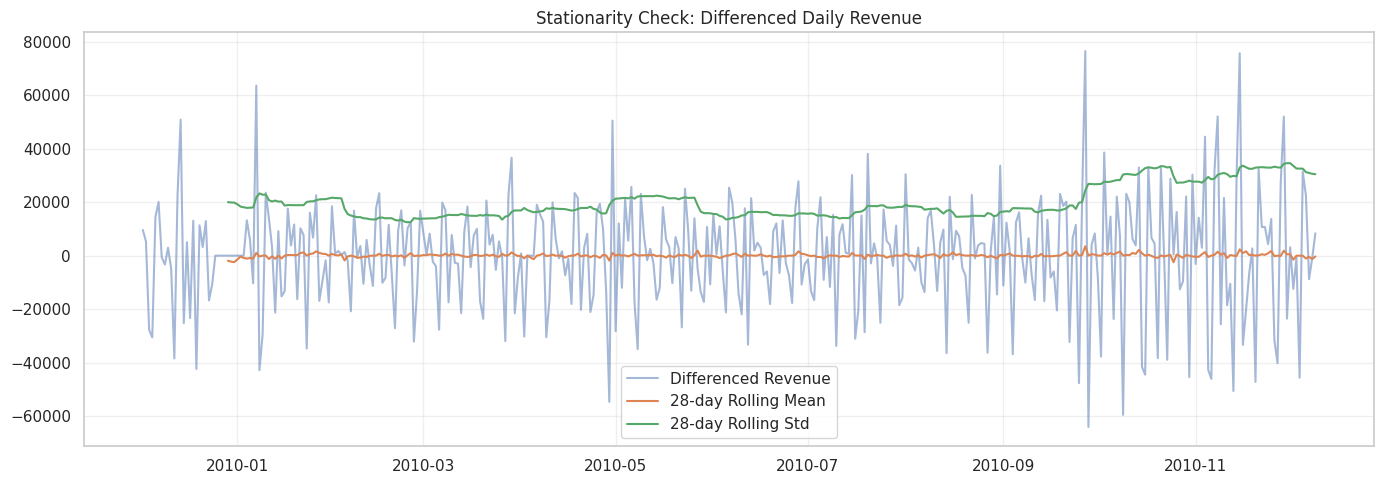

In [104]:
# Check rolling statistics after first differencing
rolling_mean = daily_revenue_diff.rolling(28).mean()
rolling_std = daily_revenue_diff.rolling(28).std()

plt.figure(figsize=(14, 5))
plt.plot(
    daily_revenue_diff.index,
    daily_revenue_diff,
    label="Differenced Revenue",
    alpha=0.5
)
plt.plot(rolling_mean.index, rolling_mean, label="28-day Rolling Mean")
plt.plot(rolling_std.index, rolling_std, label="28-day Rolling Std")
plt.title("Stationarity Check: Differenced Daily Revenue")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### Stationarity Testing

The daily revenue series was first-differenced to reduce non-stationarity. The Augmented Dickey–Fuller (ADF) test returned a p-value of 9.459 × 10⁻¹⁶, indicating strong evidence against the unit-root null hypothesis. However, the KPSS test returned a p-value of 0.04167, which is below the 0.05 significance level and indicates rejection of the stationarity null hypothesis.

These results provide mixed evidence regarding stationarity after differencing. Further investigation of rolling statistics, weekly seasonality, and potential structural changes is recommended before selecting a forecasting model.


In [105]:
daily_revenue.to_csv(
    DATA_DIR / "daily_revenue.csv",
    header=True
)

print("Daily revenue dataset saved successfully.")

Daily revenue dataset saved successfully.
